# NYC Taxi Demand Forecasting & Dynamic Pricing

**Case Study | January 2024 Yellow Taxi Trip Data**

## 1. Business Understanding

### Problem Statement
Analyze historical taxi trips, identify temporal and spatial demand patterns, forecast future demand, and develop a dynamic-pricing simulation to evaluate revenue opportunities.

### Business Objective
Develop a data-driven strategy to maximize revenue for a NYC taxi fleet by forecasting demand and evaluating surge-price multipliers across time and pickup locations.

### Context and Challenge
Surge pricing can increase fare per trip during periods of high demand, but higher prices may reduce the number of customers willing to ride.
- If the multiplier is too low, potential revenue during peak demand may be missed.
- If the multiplier is too high, demand may decline and reduce total revenue.

The pricing strategy must balance fare increases against an assumed customer response (price elasticity). **Elasticity is not directly observed in this dataset and must be treated as an assumption until validated experimentally.**

## 2. Data Loading & Understanding

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from IPython.display import Markdown, display

In [2]:
#Importing the data
file_path = "/Users/tarunraghav/Downloads/RADIX case study/yellow_tripdata_2024-01.parquet"
df = pd.read_parquet(file_path)
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0


## 3. Data Cleaning & Quality Checks

In [3]:
df.shape

(2964624, 19)

In [4]:
#Columns summary
df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'store_and_fwd_flag',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'Airport_fee']

In [5]:
#Keeping only the relevent columns & dropping others
important_columns = [
    "VendorID",
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "passenger_count",
    "trip_distance",
    "RatecodeID",
    "PULocationID",
    "DOLocationID",
    "payment_type",
    "fare_amount",
    "extra",
    "tip_amount",
    "tolls_amount",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee"
]


print("Original dataset shape:", df.shape)
df = df[important_columns]
print("EDA dataset shape:", df.shape)

Original dataset shape: (2964624, 19)
EDA dataset shape: (2964624, 16)


In [6]:
df.dtypes

VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
tip_amount                      float64
tolls_amount                    float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
dtype: object

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2964624 entries, 0 to 2964623
Data columns (total 16 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   PULocationID           int32         
 7   DOLocationID           int32         
 8   payment_type           int64         
 9   fare_amount            float64       
 10  extra                  float64       
 11  tip_amount             float64       
 12  tolls_amount           float64       
 13  total_amount           float64       
 14  congestion_surcharge   float64       
 15  Airport_fee            float64       
dtypes: datetime64[us](2), float64(10), int32(3), int64(1)
memory usage: 328.0 MB


In [8]:
df.describe()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,tip_amount,tolls_amount,total_amount,congestion_surcharge,Airport_fee
count,2.964624e+06,2964624,2964624,2.824462e+06,2.964624e+06,2.824462e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.824462e+06,2.824462e+06
mean,1.754204e+00,2024-01-17 00:46:36.431092,2024-01-17 01:02:13.208130,1.339281e+00,3.652169e+00,2.069359e+00,1.660179e+02,1.651167e+02,1.161271e+00,1.817506e+01,1.451598e+00,3.335870e+00,5.270212e-01,2.680150e+01,2.256122e+00,1.411611e-01
min,1.000000e+00,2002-12-31 22:59:39,2002-12-31 23:05:41,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,-8.990000e+02,-7.500000e+00,-8.000000e+01,-8.000000e+01,-9.000000e+02,-2.500000e+00,-1.750000e+00
25%,2.000000e+00,2024-01-09 15:59:19.750000,2024-01-09 16:16:23,1.000000e+00,1.000000e+00,1.000000e+00,1.320000e+02,1.140000e+02,1.000000e+00,8.600000e+00,0.000000e+00,1.000000e+00,0.000000e+00,1.538000e+01,2.500000e+00,0.000000e+00
50%,2.000000e+00,2024-01-17 10:45:37.500000,2024-01-17 11:03:51.500000,1.000000e+00,1.680000e+00,1.000000e+00,1.620000e+02,1.620000e+02,1.000000e+00,1.280000e+01,1.000000e+00,2.700000e+00,0.000000e+00,2.010000e+01,2.500000e+00,0.000000e+00
75%,2.000000e+00,2024-01-24 18:23:52.250000,2024-01-24 18:40:29,1.000000e+00,3.110000e+00,1.000000e+00,2.340000e+02,2.340000e+02,1.000000e+00,2.050000e+01,2.500000e+00,4.120000e+00,0.000000e+00,2.856000e+01,2.500000e+00,0.000000e+00
max,6.000000e+00,2024-02-01 00:01:15,2024-02-02 13:56:52,9.000000e+00,3.127223e+05,9.900000e+01,2.650000e+02,2.650000e+02,4.000000e+00,5.000000e+03,1.425000e+01,4.280000e+02,1.159200e+02,5.000000e+03,2.500000e+00,1.750000e+00
std,4.325902e-01,NaN,NaN,8.502817e-01,2.254626e+02,9.823219e+00,6.362391e+01,6.931535e+01,5.808686e-01,1.894955e+01,1.804102e+00,3.896551e+00,2.128310e+00,2.338558e+01,8.232747e-01,4.876239e-01


### Initial data-quality observations
- Pickup timestamps extend beyond the intended January 2024 analysis window; we will filter using **pickup datetime**.
- Some fare values are zero or negative.
- Their treatment depends on the analysis:they may be excluded from fare/revenue analysis, but should not automatically be removed from pickup-demand counts if the pickup event is valid.

#### Missing value identifications & Analysis

In [9]:
#Checking for missing values
df.isna().sum()

VendorID                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          140162
trip_distance                 0
RatecodeID               140162
PULocationID                  0
DOLocationID                  0
payment_type                  0
fare_amount                   0
extra                         0
tip_amount                    0
tolls_amount                  0
total_amount                  0
congestion_surcharge     140162
Airport_fee              140162
dtype: int64

In [10]:
# Check missing values by combinations of columns

missing_cols = [
    "passenger_count",
    "RatecodeID",
    "congestion_surcharge",
    "Airport_fee"
]

df[missing_cols].isnull().sum()

passenger_count         140162
RatecodeID              140162
congestion_surcharge    140162
Airport_fee             140162
dtype: int64

In [11]:
#Analysis of missing values
# Are all these missing values occurring in the same rows?

missing_pattern = df[missing_cols].isnull().all(axis=1)

print("Rows missing in all 4 columns:", missing_pattern.sum())

print("Rows missing in at least one column:",
      df[missing_cols].isnull().any(axis=1).sum())

Rows missing in all 4 columns: 140162
Rows missing in at least one column: 140162


In [12]:
# Create a flag
df["missing_info_flag"] = missing_pattern

# Compare groups
comparison = df.groupby("missing_info_flag").agg(
    trip_count=("missing_info_flag", "count"),
    avg_distance=("trip_distance", "mean"),
    avg_fare=("fare_amount", "mean"),
    avg_total_amount=("total_amount", "mean"),
    avg_passenger_count=("passenger_count", "mean")
)

display(comparison)

pd.crosstab(
    df["missing_info_flag"],
    df["VendorID"],
    normalize="index"
) * 100

,trip_count,avg_distance,avg_fare,avg_total_amount,avg_passenger_count
missing_info_flag,,,,,
False,2824462,3.254071,18.083697,26.850621,1.339281
True,140162,11.674403,20.016194,25.811737,NaN


VendorID,1,2,6
missing_info_flag,,,
False,24.120594,75.879406,0.0000
True,34.570711,65.243789,0.1855


### Missing-value Observations
- Approximately 140,162 records have missing values occurring together in passenger count, rate code, congestion surcharge, and airport fee.
- These records have different trip characteristics from records with complete information.

They are **not removed or imputed indiscriminately**. For pickup-demand analysis, records can still be useful when pickup datetime and pickup location are valid. For analyses involving the missing attributes, use an analysis-specific treatment and document it.

### DUPLICATE CHECKS

In [13]:
df.duplicated().sum()

0

### Data Type: Checks

In [14]:
df.dtypes

VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
tip_amount                      float64
tolls_amount                    float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
missing_info_flag                  bool
dtype: object

### Date Range Checks

### Date-range decision
- The case study focuses on January 2024. Filter trips by **pickup datetime** to retain pickups from **January 1 through January 31**.
- A trip picked up on January 31 may legitimately have a drop-off timestamp in February, so we should not filter by drop-off datetime.

In [15]:
#Data : Date Range Summary
df[['tpep_pickup_datetime', 'tpep_dropoff_datetime']].describe()

,tpep_pickup_datetime,tpep_dropoff_datetime
count,2964624,2964624
mean,2024-01-17 00:46:36.431092,2024-01-17 01:02:13.208130
min,2002-12-31 22:59:39,2002-12-31 23:05:41
25%,2024-01-09 15:59:19.750000,2024-01-09 16:16:23
50%,2024-01-17 10:45:37.500000,2024-01-17 11:03:51.500000
75%,2024-01-24 18:23:52.250000,2024-01-24 18:40:29
max,2024-02-01 00:01:15,2024-02-02 13:56:52


In [16]:
b = len(df)
print("Rows before filtering:", b)

# Filtering Date Range: 
start_date = "2024-01-01"
end_date = "2024-02-01"

# Keep January pickup records only
df = df[
    (df["tpep_pickup_datetime"] >= start_date) &
    (df["tpep_pickup_datetime"] < end_date)
]


print("Rows after filtering:", len(df))
print("Rows removed:", b - len(df))

Rows before filtering: 2964624
Rows after filtering: 2964606
Rows removed: 18


# Feature Engineering

#### Distance Outlier Treatments

In [17]:
#Calculation of Duration of trip in mins
from datetime import datetime as dt

df["trip_duration_minutes"] = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60

In [18]:
#Checking for Un-usual travel behaviours
print("Missing pickup timestamps:",
      df["tpep_pickup_datetime"].isna().sum())

print("Missing dropoff timestamps:",
      df["tpep_dropoff_datetime"].isna().sum())

print("Dropoff before pickup:",
      (df["tpep_dropoff_datetime"] <
       df["tpep_pickup_datetime"]).sum())

print("Zero/negative trip duration:",
      (df["trip_duration_minutes"] <= 0).sum())

Missing pickup timestamps: 0
Missing dropoff timestamps: 0
Dropoff before pickup: 56
Zero/negative trip duration: 870


**Duration quality check**
- Trips with non-positive duration are flagged for investigation. Whether they are excluded depends on the analysis.
- They should not be automatically removed from a demand dataset if their pickup timestamp and pickup location are valid.

In [19]:
# Count negative vs zero duration
print("Negative duration:",(df["trip_duration_minutes"] < 0).sum())

print("Zero duration:",(df["trip_duration_minutes"] == 0).sum())

# View suspicious records
invalid_duration = df[
    df["trip_duration_minutes"] <= 0
]

invalid_duration[
    [
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "trip_duration_minutes",
        "trip_distance",
        "fare_amount",
        "PULocationID",
        "DOLocationID"
    ]
].head(10)

Negative duration: 56
Zero duration: 814


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_minutes,trip_distance,fare_amount,PULocationID,DOLocationID
23,2024-01-01 00:14:29,2024-01-01 00:14:29,0.0,0.0,3.00,236,264
16790,2024-01-01 02:47:57,2024-01-01 02:47:57,0.0,0.0,52.50,61,61
17277,2024-01-01 03:18:03,2024-01-01 03:18:03,0.0,0.0,33.99,246,264
19195,2024-01-01 03:06:02,2024-01-01 03:06:02,0.0,0.0,35.22,113,264
21393,2024-01-01 04:08:24,2024-01-01 04:08:24,0.0,0.0,10.70,249,264
22868,2024-01-01 04:06:44,2024-01-01 04:06:44,0.0,0.0,14.51,137,264
23585,2024-01-01 05:21:13,2024-01-01 05:21:13,0.0,0.0,0.00,48,264
25800,2024-01-01 07:33:54,2024-01-01 07:33:54,0.0,0.0,66.70,223,264
25801,2024-01-01 07:40:28,2024-01-01 07:40:28,0.0,0.0,46.00,223,264
28009,2024-01-01 09:24:09,2024-01-01 09:24:09,0.0,0.0,3.00,238,264


**Decision:** 
- Non-positive-duration trips are invalid for trip-duration analysis.
- However, retain valid pickup events in a separate demand dataset;
- removing them from the only dataframe could undercount demand.

In [20]:
print(f"Trip dataframe before dropping: {df.shape[0]}")
df = df[df["trip_duration_minutes"] > 0]
print(f"Trip dataframe After dropping: {df.shape[0]}")

Trip dataframe before dropping: 2964606
Trip dataframe After dropping: 2963736


In [21]:
#Checking of Outlier: Numeric values
df.describe()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,tip_amount,tolls_amount,total_amount,congestion_surcharge,Airport_fee,trip_duration_minutes
count,2.963736e+06,2963736,2963736,2.823685e+06,2.963736e+06,2.823685e+06,2.963736e+06,2.963736e+06,2.963736e+06,2.963736e+06,2.963736e+06,2.963736e+06,2.963736e+06,2.963736e+06,2.823685e+06,2.823685e+06,2.963736e+06
mean,1.754302e+00,2024-01-17 01:02:03.348798,2024-01-17 01:17:40.403193,1.339301e+00,3.653028e+00,2.067945e+00,1.660133e+02,1.650936e+02,1.161125e+00,1.816763e+01,1.451425e+00,3.336575e+00,5.270277e-01,2.679521e+01,2.256349e+00,1.411597e-01,1.561757e+01
min,1.000000e+00,2024-01-01 00:00:00,2024-01-01 00:02:42,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,-8.990000e+02,-7.500000e+00,-8.000000e+01,-8.000000e+01,-9.000000e+02,-2.500000e+00,-1.750000e+00,1.666667e-02
25%,2.000000e+00,2024-01-09 15:59:24.750000,2024-01-09 16:16:28,1.000000e+00,1.000000e+00,1.000000e+00,1.320000e+02,1.140000e+02,1.000000e+00,8.600000e+00,0.000000e+00,1.000000e+00,0.000000e+00,1.538000e+01,2.500000e+00,0.000000e+00,7.150000e+00
50%,2.000000e+00,2024-01-17 10:45:36,2024-01-17 11:03:49,1.000000e+00,1.680000e+00,1.000000e+00,1.620000e+02,1.620000e+02,1.000000e+00,1.280000e+01,1.000000e+00,2.700000e+00,0.000000e+00,2.010000e+01,2.500000e+00,0.000000e+00,1.163333e+01
75%,2.000000e+00,2024-01-24 18:23:48.250000,2024-01-24 18:40:27,1.000000e+00,3.110000e+00,1.000000e+00,2.340000e+02,2.340000e+02,1.000000e+00,2.050000e+01,2.500000e+00,4.120000e+00,0.000000e+00,2.856000e+01,2.500000e+00,0.000000e+00,1.868333e+01
max,6.000000e+00,2024-01-31 23:59:55,2024-02-02 13:56:52,9.000000e+00,3.127223e+05,9.900000e+01,2.650000e+02,2.650000e+02,4.000000e+00,2.221300e+03,1.425000e+01,4.280000e+02,1.159200e+02,2.225300e+03,2.500000e+00,1.750000e+00,9.455400e+03
std,4.321277e-01,NaN,NaN,8.502100e-01,2.254963e+02,9.817086e+00,6.362159e+01,6.930632e+01,5.807536e-01,1.831721e+01,1.803993e+00,3.896379e+00,2.127687e+00,2.287902e+01,8.230160e-01,4.876247e-01,3.485522e+01


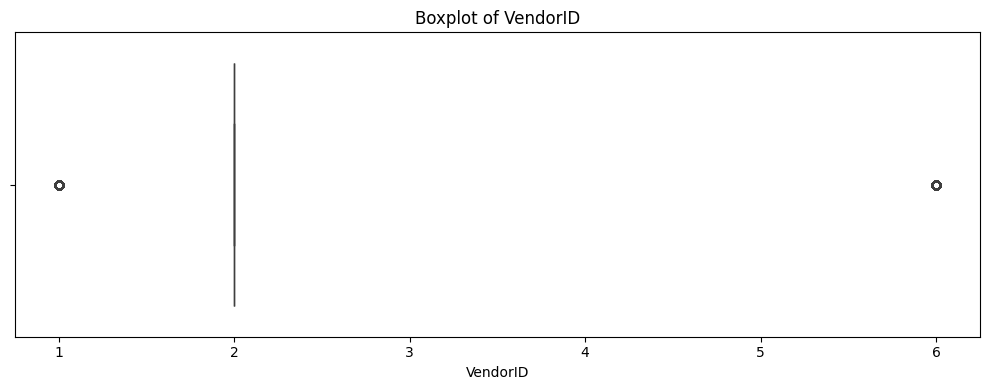

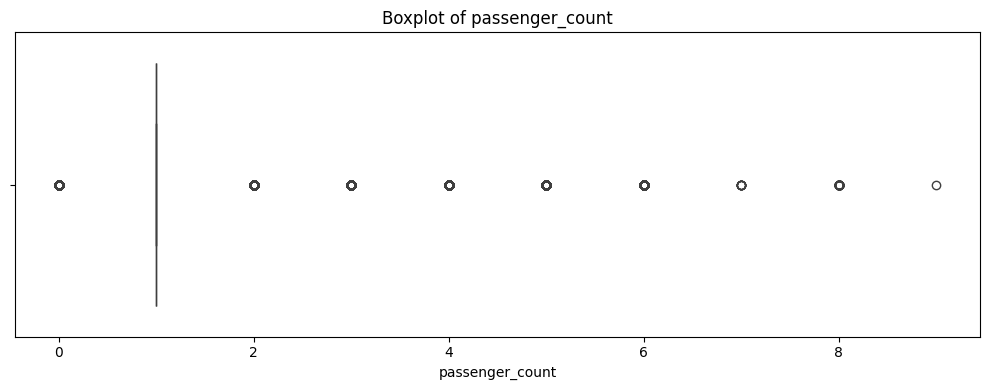

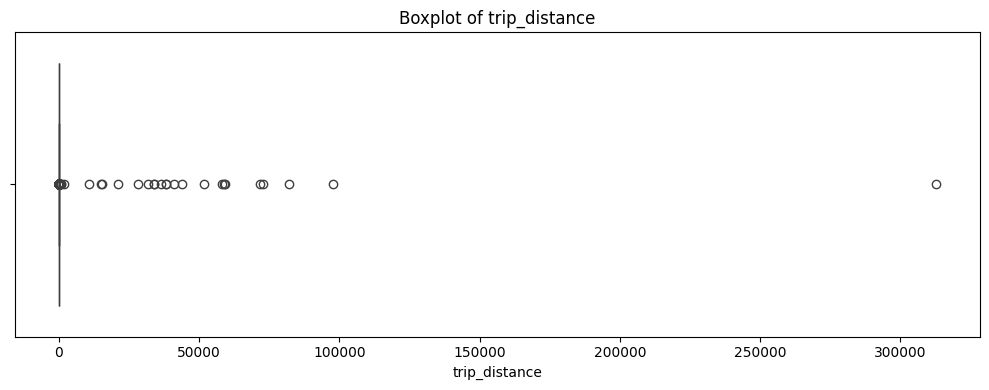

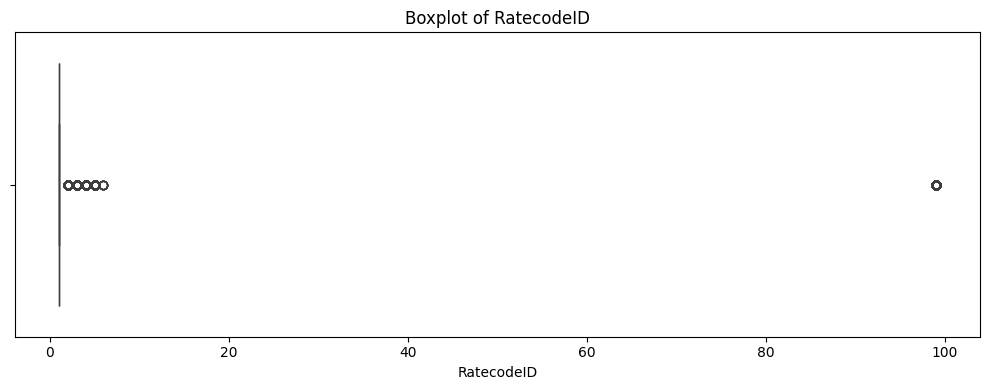

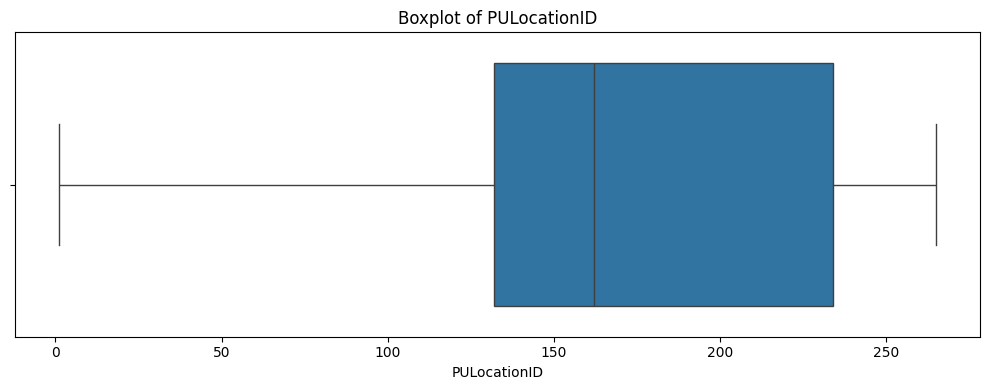

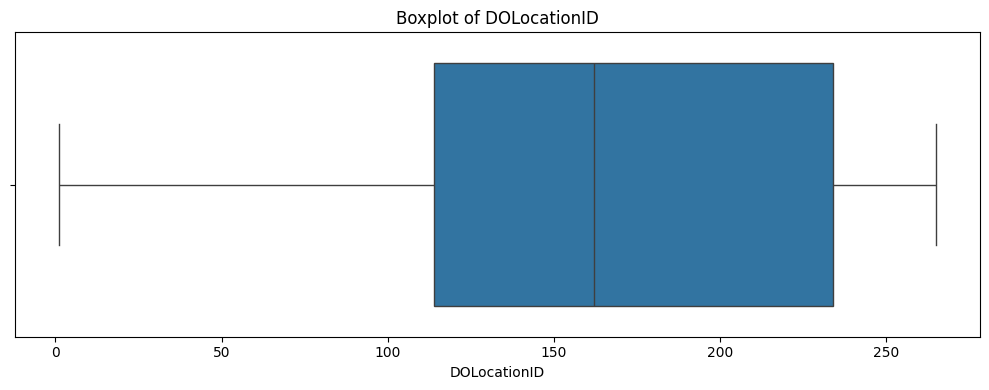

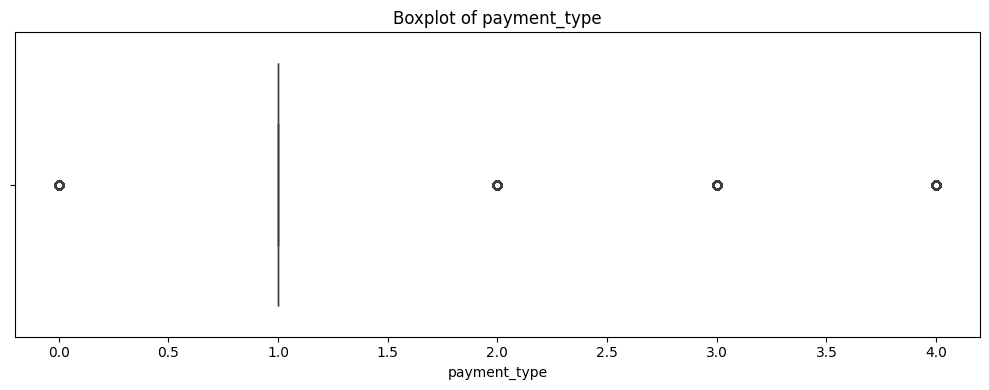

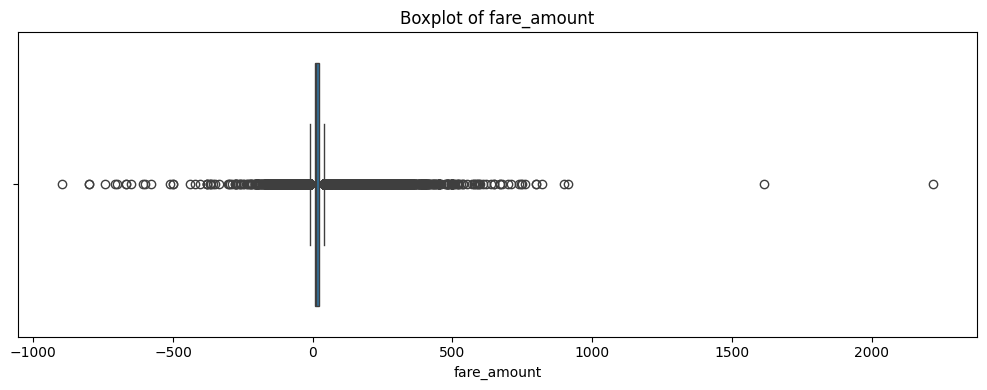

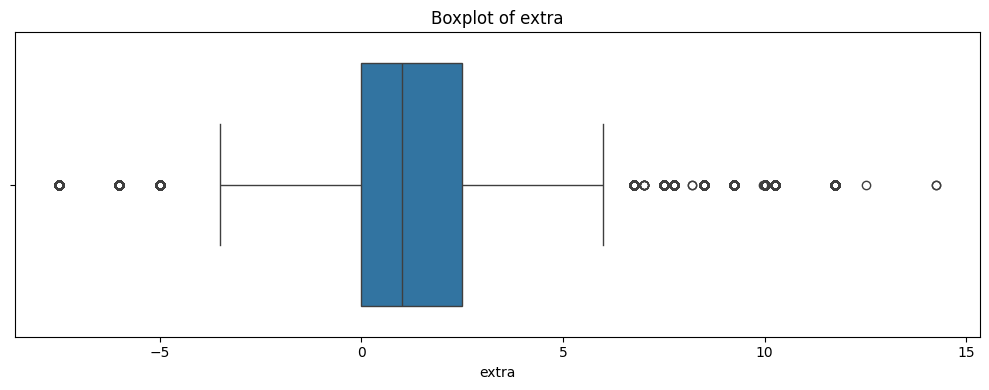

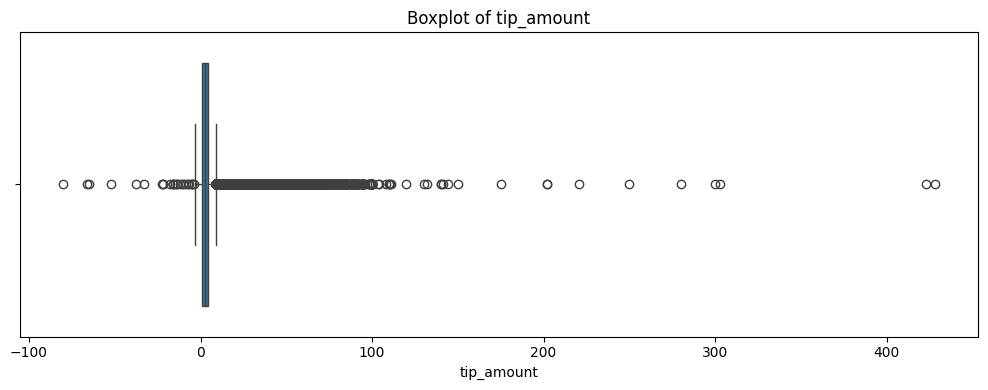

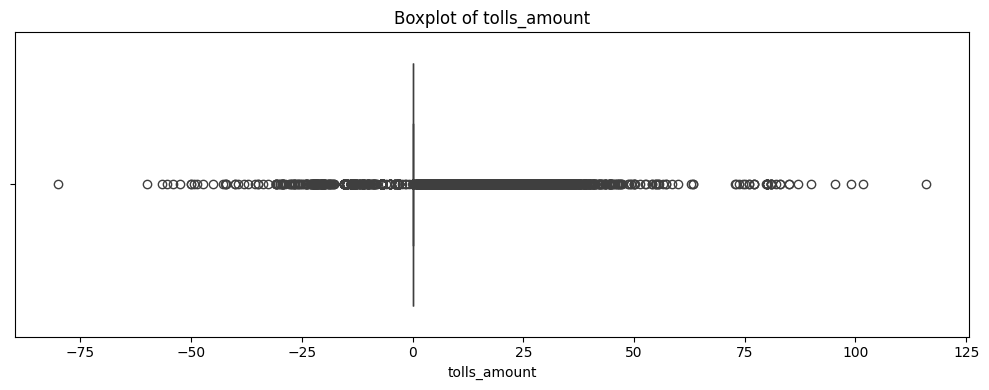

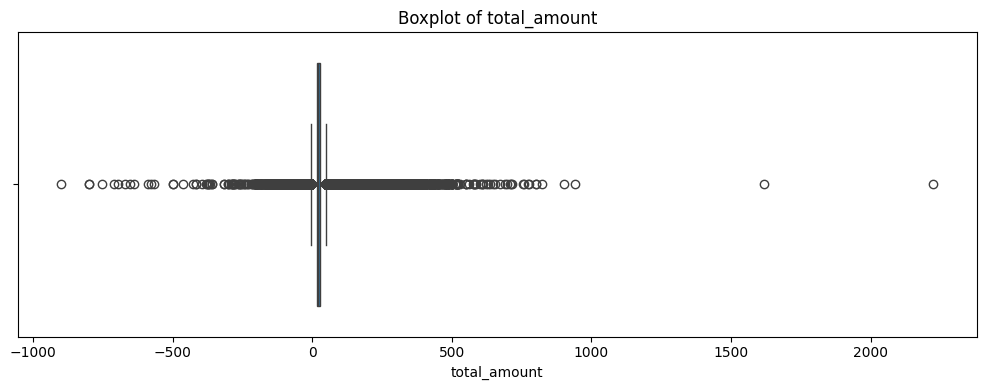

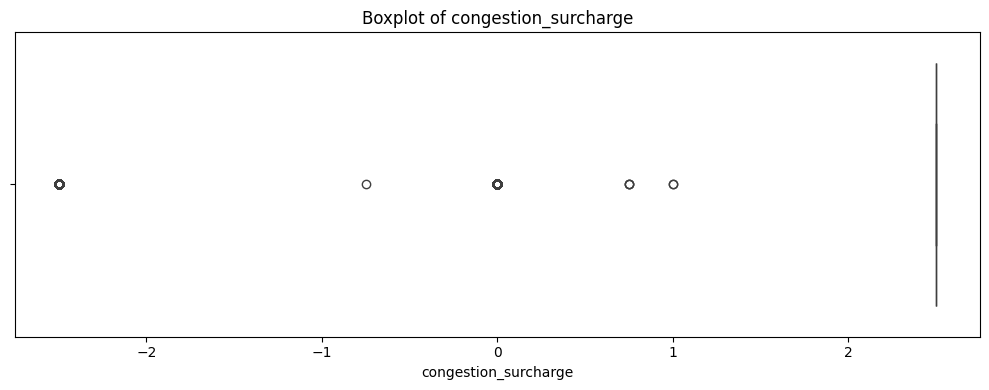

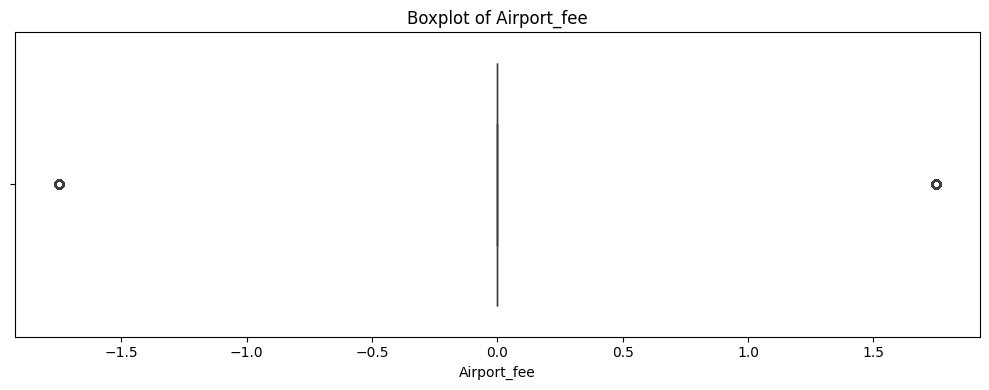

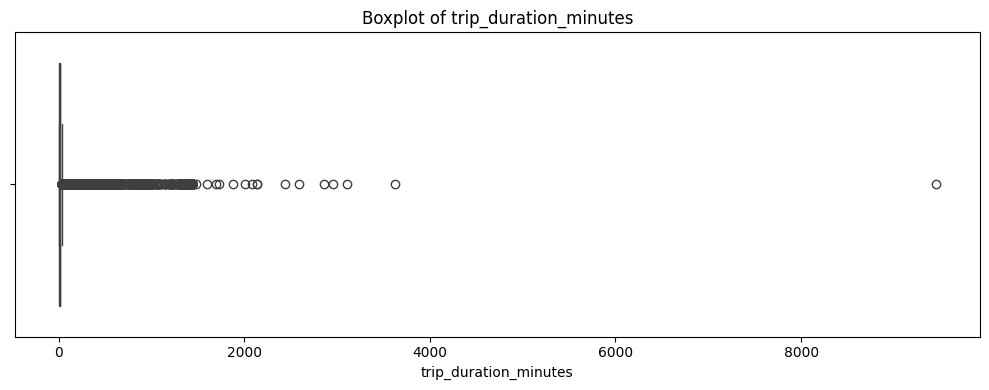

In [22]:
def plot_boxplots(data, columns, figsize=(10, 4)):
    '''This will be used to plot a box plot of the numeric value'''

    for col in columns:
        plt.figure(figsize=figsize)

        sns.boxplot(x=data[col])

        plt.title(f"Boxplot of {col}")
        plt.xlabel(col)

        plt.tight_layout()
        plt.show()



numeric_columns = ['VendorID', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'tip_amount', 'tolls_amount', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'trip_duration_minutes']

plot_boxplots(df, numeric_columns)

### Boxplot observations and treatment decisions
- **Passenger count:** Values such as zero or unusually high counts require review. Retain for now; do not use as a core demand feature until validated.
- **Trip distance:** Extreme values are flagged for investigation. Not removing solely because they are statistical outliers; some may represent long trips.
- **Fare amount:** Zero/negative fares require separate treatment for fare/revenue analysis. Very high fares are investigated rather than automatically deleted.
- **Trip duration:** Non-positive durations are invalid for duration analysis. Very long durations are suspicious, but a 48-hour cutoff must be explicitly justified and applied if chosen.

#### Handling Fare amount

In [23]:
df['fare_amount'].describe()

count    2.963736e+06
mean     1.816763e+01
std      1.831721e+01
min     -8.990000e+02
25%      8.600000e+00
50%      1.280000e+01
75%      2.050000e+01
max      2.221300e+03
Name: fare_amount, dtype: float64

In [24]:
#Checking the dair amount out of range
print(f"Checking the fair amount out of range :{len(df[df['fare_amount']<= 0])}")
#We will be removing any negative fair amount

Checking the fair amount out of range :38270


In [25]:
print(f"Counts before removal of outlier amounts: {df.shape[0]}")
df = df[df['fare_amount']> 0]

print(f"Counts After removal of outlier amounts: {df.shape[0]}")

Counts before removal of outlier amounts: 2963736
Counts After removal of outlier amounts: 2925466


#### Trip Duration Handling

In [26]:
#Checking for invalid trips: If found any we will be dropping the same
print(f"Checking for 0 & -ve Trip durations: {df[df['trip_duration_minutes']<=0].shape[0] }")


Checking for 0 & -ve Trip durations: 0


#### Checking for longer & higher trips: if legitimate or not

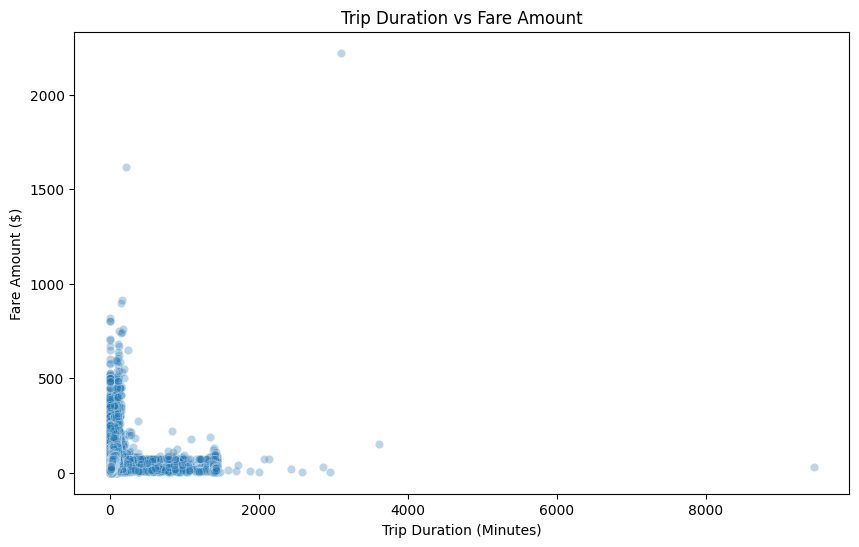

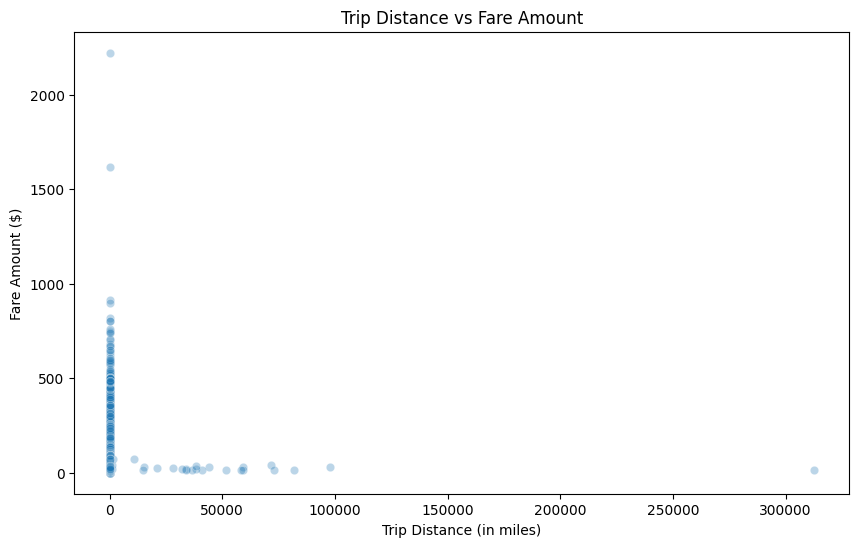

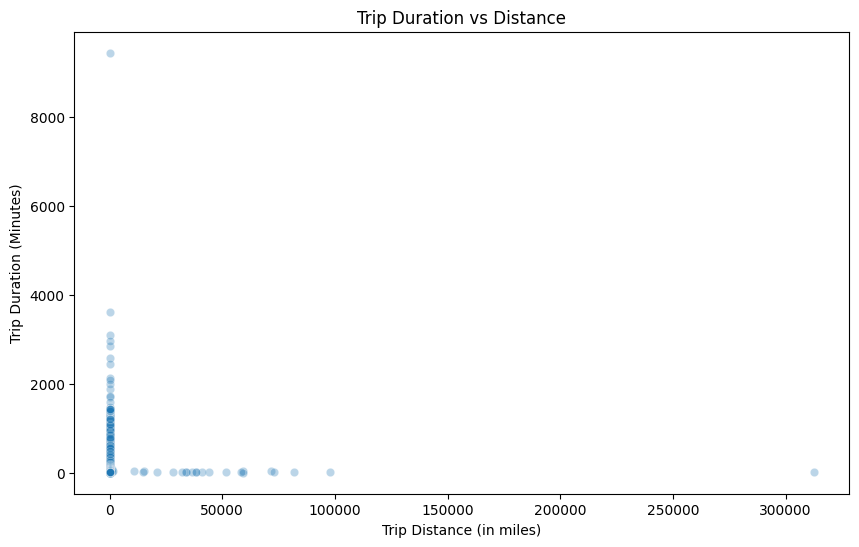

In [27]:
#To check the fare vs duration behaviour
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="trip_duration_minutes",
    y="fare_amount",
    alpha=0.3
)

plt.title("Trip Duration vs Fare Amount")
plt.xlabel("Trip Duration (Minutes)")
plt.ylabel("Fare Amount ($)")
plt.show()



###############################
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="trip_distance",
    y="fare_amount",
    alpha=0.3
)

plt.title("Trip Distance vs Fare Amount")
plt.xlabel("Trip Distance (in miles)")
plt.ylabel("Fare Amount ($)")
plt.show()



###############################
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="trip_distance",
    y="trip_duration_minutes",
    alpha=0.3
)

plt.title("Trip Duration vs Distance")
plt.xlabel("Trip Distance (in miles)")
plt.ylabel("Trip Duration (Minutes)")
plt.show()

### Scatterplot observations
- Fare and duration do not always align; some short-duration trips have high fares.
- Some records have zero distance despite positive duration.
- Some zero-distance records have unusually high fares.

These are investigation signals, not proof that every such record is erroneous.

In [28]:
import numpy as np
import pandas as pd

# High-fare trips (> $200)
sub = df.loc[
    df["fare_amount"] > 200,
    ["fare_amount", "trip_distance", "trip_duration_minutes"]
].copy()

# Fare per mile
sub["fare_per_mile"] = (
    sub["fare_amount"] / sub["trip_distance"].replace(0, np.nan)
)

# Assessment
sub["assessment"] = np.select(
    [
        (sub["trip_distance"] >= 30) &
        (sub["fare_per_mile"].between(2, 10)),

        (sub["trip_distance"] < 1) |
        (sub["trip_duration_minutes"] < 1)
    ],
    [
        "Plausible long trip (distance explains fare)",
        "Contradictory (huge fare, ~no distance/time)"
    ],
    default="Needs review (fare/distance ratio unusual)"
)

print(f"Trips with fare > $200: {len(sub):,}")

display(
    sub["assessment"]
    .value_counts()
    .rename("trips")
    .to_frame()
)

# Statistical view of df (already core-valid)
core_view = df[
    ["fare_amount", "trip_distance", "trip_duration_minutes"]
].copy()

# Quantiles
q = core_view.quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]
).T

# IQR upper fence
q["IQR_upper_fence"] = (
    core_view.quantile(0.75) +
    1.5 * (
        core_view.quantile(0.75) -
        core_view.quantile(0.25)
    )
)

# Number of observations above upper fence
q["n_above_fence"] = [
    (core_view[col] > q.loc[col, "IQR_upper_fence"]).sum()
    for col in q.index
]

display(q)

Trips with fare > $200: 1,061


,trips
assessment,
Plausible long trip (distance explains fare),822
"Contradictory (huge fare, ~no distance/time)",195
Needs review (fare/distance ratio unusual),44


,0.01,0.05,0.25,0.5,0.75,0.95,0.99,0.999,IQR_upper_fence,n_above_fence
fare_amount,4.400000,5.800000,8.6,12.800000,20.500000,62.500000,76.500000,145.500000,38.350000,297207
trip_distance,0.000000,0.450000,1.0,1.690000,3.120000,13.660000,20.000000,29.440000,6.300000,375347
trip_duration_minutes,1.033333,3.366667,7.2,11.666667,18.716667,37.966667,60.483333,115.183333,35.991667,168870


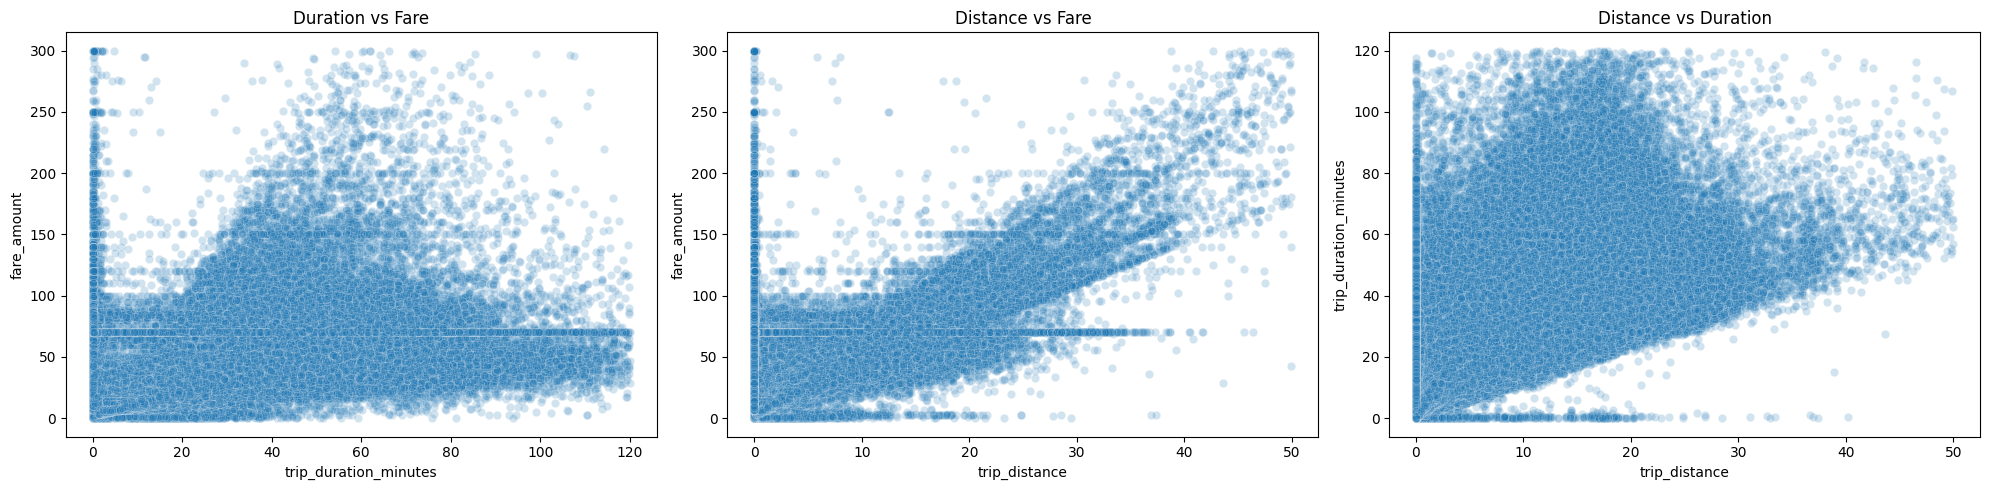

In [29]:
#Checking trend of them wrt each other and noting the observations
plot_data = df[
    (df["trip_duration_minutes"] <= 120) &
    (df["trip_distance"] <= 50) &
    (df["fare_amount"] <= 300)
].copy()


fig, axes = plt.subplots(1, 3, figsize=(20, 5))

sns.scatterplot(
    data=plot_data,
    x="trip_duration_minutes",
    y="fare_amount",
    alpha=0.2,
    ax=axes[0]
)
axes[0].set_title("Duration vs Fare")

sns.scatterplot(
    data=plot_data,
    x="trip_distance",
    y="fare_amount",
    alpha=0.2,
    ax=axes[1]
)
axes[1].set_title("Distance vs Fare")

sns.scatterplot(
    data=plot_data,
    x="trip_distance",
    y="trip_duration_minutes",
    alpha=0.2,
    ax=axes[2]
)
axes[2].set_title("Distance vs Duration")

plt.tight_layout()
plt.show()

**EDA finding**
- Trip distance, duration, and fare generally increase together within the visualization range.
- The full dataset contains extreme observations that obscure this pattern.
- The restricted dataset is used **only to improve visualization**, not as a final cleaned dataset or a demand-analysis filter.

In [30]:
############ Overall data 
print(" Overall data  ")
#Pearson Correlation
print("Pearson Correlation:")
correlation_data = df[
    ["trip_distance", "trip_duration_minutes", "fare_amount"]
].corr(method="pearson")

display(correlation_data)

print("Spearman Correlation:")
#spearman Correlation
display(df[
    ["trip_distance", "trip_duration_minutes", "fare_amount"]
].corr(method="spearman"))


print(" By removing extreme data   ")
############# By removing extreme data 
print("Pearson Correlation:")
display(
    plot_data[
        ["trip_distance", "trip_duration_minutes", "fare_amount"]
    ].corr(method="pearson")
)

print("Spearman Correlation:")
display(
    plot_data[
        ["trip_distance", "trip_duration_minutes", "fare_amount"]
    ].corr(method="spearman")
)

 Overall data  
Pearson Correlation:


,trip_distance,trip_duration_minutes,fare_amount
trip_distance,1.000000,0.005321,0.017563
trip_duration_minutes,0.005321,1.000000,0.268822
fare_amount,0.017563,0.268822,1.000000


Spearman Correlation:


,trip_distance,trip_duration_minutes,fare_amount
trip_distance,1.000000,0.841333,0.883548
trip_duration_minutes,0.841333,1.000000,0.929663
fare_amount,0.883548,0.929663,1.000000


 By removing extreme data   
Pearson Correlation:


,trip_distance,trip_duration_minutes,fare_amount
trip_distance,1.000000,0.788254,0.908310
trip_duration_minutes,0.788254,1.000000,0.791195
fare_amount,0.908310,0.791195,1.000000


Spearman Correlation:


,trip_distance,trip_duration_minutes,fare_amount
trip_distance,1.000000,0.842078,0.883610
trip_duration_minutes,0.842078,1.000000,0.930726
fare_amount,0.883610,0.930726,1.000000


**Correlation interpretation**
- Extreme values materially affect Pearson correlation.
- After applying visualization-only limits, Pearson correlations become stronger.
- Spearman correlations are comparatively stable, indicating strong monotonic relationships.

**Caution:** 
- This comparison demonstrates sensitivity to the selected visualization limits;
- it does not justify deleting all observations outside those limits from the analytical dataset.

In [31]:
######## We will keep important columns only for our case study
important_columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID",
    "trip_distance",
    "trip_duration_minutes",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "passenger_count"
]

df_analysis = df[important_columns].copy()
df_analysis.head()

,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID,trip_distance,trip_duration_minutes,fare_amount,tip_amount,total_amount,passenger_count
0,2024-01-01 00:57:55,2024-01-01 01:17:43,186,79,1.72,19.800000,17.7,0.00,22.70,1.0
1,2024-01-01 00:03:00,2024-01-01 00:09:36,140,236,1.80,6.600000,10.0,3.75,18.75,1.0
2,2024-01-01 00:17:06,2024-01-01 00:35:01,236,79,4.70,17.916667,23.3,3.00,31.30,1.0
3,2024-01-01 00:36:38,2024-01-01 00:44:56,79,211,1.40,8.300000,10.0,2.00,17.00,1.0
4,2024-01-01 00:46:51,2024-01-01 00:52:57,211,148,0.80,6.100000,7.9,3.20,16.10,1.0


## 4. Exploratory Data Analysis (EDA)

This section explores demand over time and across pickup zones. The demand analysis should use valid pickup events, not filters based on fare or trip duration unless those filters are specifically justified for demand.

In [32]:
df_analysis.shape

(2925466, 10)

In [33]:
df_analysis.dtypes

tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
PULocationID                      int32
DOLocationID                      int32
trip_distance                   float64
trip_duration_minutes           float64
fare_amount                     float64
tip_amount                      float64
total_amount                    float64
passenger_count                 float64
dtype: object

In [34]:
df_analysis.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2925466 entries, 0 to 2964623
Data columns (total 10 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   tpep_pickup_datetime   datetime64[us]
 1   tpep_dropoff_datetime  datetime64[us]
 2   PULocationID           int32         
 3   DOLocationID           int32         
 4   trip_distance          float64       
 5   trip_duration_minutes  float64       
 6   fare_amount            float64       
 7   tip_amount             float64       
 8   total_amount           float64       
 9   passenger_count        float64       
dtypes: datetime64[us](2), float64(6), int32(2)
memory usage: 223.2 MB


In [35]:
df_analysis.reset_index(drop=True, inplace=True)

### Time-based feature engineering

In [36]:
df_analysis["pickup_date"] = df_analysis["tpep_pickup_datetime"].dt.date

df_analysis["pickup_hour"] = df_analysis["tpep_pickup_datetime"].dt.hour

df_analysis["pickup_day"] = df_analysis["tpep_pickup_datetime"].dt.day

df_analysis["pickup_day_of_week"] = df_analysis["tpep_pickup_datetime"].dt.dayofweek

df_analysis["pickup_month"] = df_analysis["tpep_pickup_datetime"].dt.month

df_analysis["is_weekend"] = (
    df_analysis["pickup_day_of_week"] >= 5
)

In [37]:
df_analysis

,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID,trip_distance,trip_duration_minutes,fare_amount,tip_amount,total_amount,passenger_count,pickup_date,pickup_hour,pickup_day,pickup_day_of_week,pickup_month,is_weekend
0,2024-01-01 00:57:55,2024-01-01 01:17:43,186,79,1.72,19.800000,17.70,0.00,22.70,1.0,2024-01-01,0,1,0,1,False
1,2024-01-01 00:03:00,2024-01-01 00:09:36,140,236,1.80,6.600000,10.00,3.75,18.75,1.0,2024-01-01,0,1,0,1,False
2,2024-01-01 00:17:06,2024-01-01 00:35:01,236,79,4.70,17.916667,23.30,3.00,31.30,1.0,2024-01-01,0,1,0,1,False
3,2024-01-01 00:36:38,2024-01-01 00:44:56,79,211,1.40,8.300000,10.00,2.00,17.00,1.0,2024-01-01,0,1,0,1,False
4,2024-01-01 00:46:51,2024-01-01 00:52:57,211,148,0.80,6.100000,7.90,3.20,16.10,1.0,2024-01-01,0,1,0,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925461,2024-01-31 23:45:59,2024-01-31 23:54:36,107,263,3.18,8.616667,15.77,2.00,21.77,NaN,2024-01-31,23,31,2,1,False
2925462,2024-01-31 23:13:07,2024-01-31 23:27:52,114,236,4.00,14.750000,18.40,2.34,25.74,NaN,2024-01-31,23,31,2,1,False
2925463,2024-01-31 23:19:00,2024-01-31 23:38:00,211,25,3.33,19.000000,19.97,0.00,23.97,NaN,2024-01-31,23,31,2,1,False
2925464,2024-01-31 23:07:23,2024-01-31 23:25:14,107,13,3.06,17.850000,23.88,5.58,33.46,NaN,2024-01-31,23,31,2,1,False


##  Daily Demand Analysis

pickup_date
2024-01-01     79657
2024-01-02     74380
2024-01-03     81247
2024-01-04    101550
2024-01-05    101790
2024-01-06     95770
2024-01-07     66537
2024-01-08     78935
2024-01-09     92776
2024-01-10     93917
2024-01-11    103745
2024-01-12    102372
2024-01-13    103364
2024-01-14     93105
2024-01-15     76050
2024-01-16     91953
2024-01-17    109026
2024-01-18    109022
2024-01-19     94685
2024-01-20    107300
2024-01-21     83266
2024-01-22     84467
2024-01-23     98624
2024-01-24    103843
2024-01-25    108962
2024-01-26    104359
2024-01-27    108980
2024-01-28     91425
2024-01-29     83444
2024-01-30    100033
2024-01-31    100882
dtype: int64

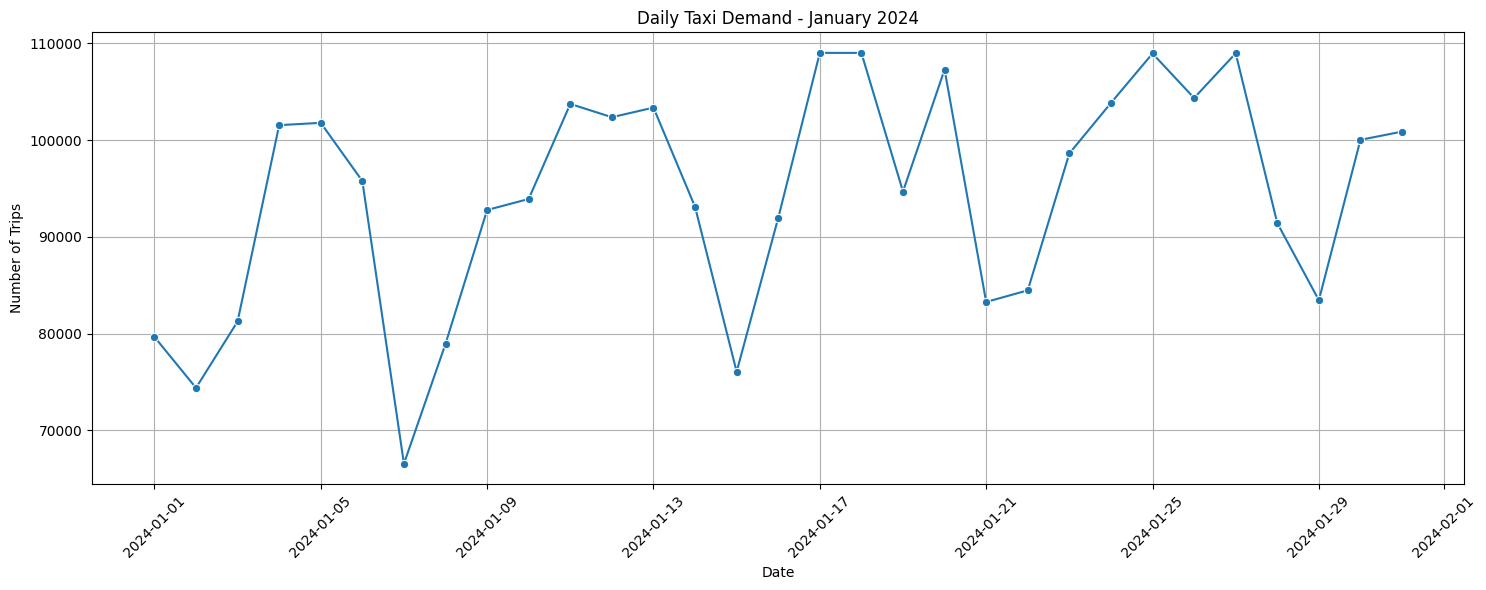

In [38]:
daily_demand = df_analysis.groupby("pickup_date").size()

display(daily_demand)



plt.figure(figsize=(15, 6))

sns.lineplot(
    x=daily_demand.index,
    y=daily_demand.values,
    marker="o"
)

plt.title("Daily Taxi Demand - January 2024")
plt.xlabel("Date")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [39]:
print("Average daily demand:", daily_demand.mean())
print("Maximum daily demand:", daily_demand.max())
print("Minimum daily demand:", daily_demand.min())
print("Peak demand date:", daily_demand.idxmax())
print("Lowest demand date:", daily_demand.idxmin())

Average daily demand: 94369.87096774194
Maximum daily demand: 109026
Minimum daily demand: 66537
Peak demand date: 2024-01-17
Lowest demand date: 2024-01-07


### Business interpretation
- Daily demand varies, so fleet capacity should not be held constant across every day.
- High-demand days may require more driver availability, while low-demand periods may require less supply.
- Forecasting should account for calendar patterns and other potential drivers.

#### Weekday vs Weekend analysis

Monday       402553
Tuesday      457766
Wednesday    488915
Thursday     423279
Friday       403206
Saturday     415414
Sunday       334333
dtype: int64

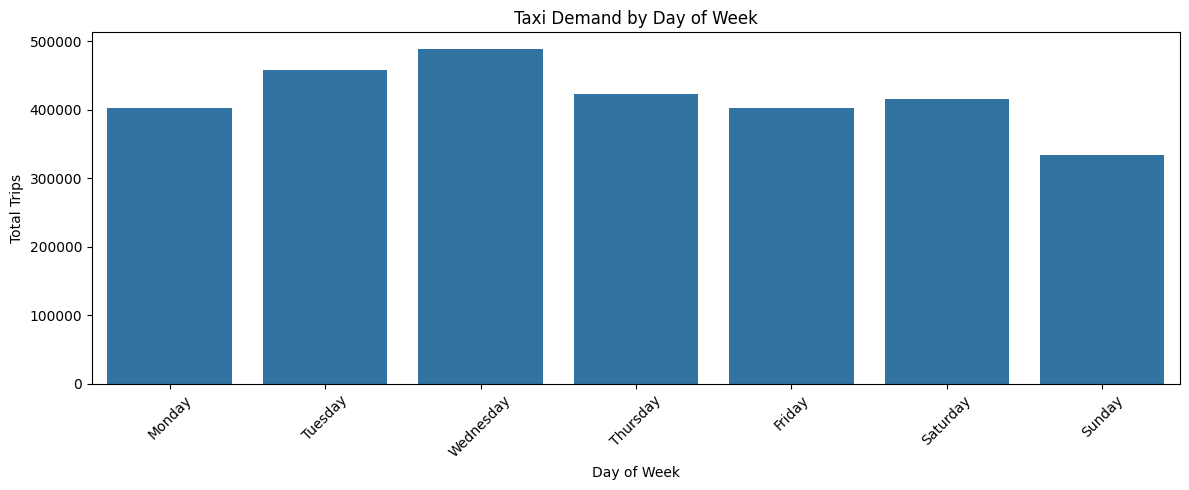

In [40]:
weekday_demand = df_analysis.groupby("pickup_day_of_week").size()

weekday_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_demand.index = weekday_names

display(weekday_demand)


####### Graphical analysis
plt.figure(figsize=(12, 5))

sns.barplot(
    x=weekday_demand.index,
    y=weekday_demand.values
)

plt.title("Taxi Demand by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Total Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation
- Raw weekday totals are not directly comparable because January contains different numbers of each weekday.
- We therefore compare **average trips per occurrence of each weekday** in the next step.

In [41]:
weekday_daily_avg = (
    df_analysis.groupby(["pickup_day_of_week", "pickup_date"])
    .size()
    .groupby(level=0)
    .mean()
)

weekday_counts = df_analysis.groupby("pickup_day_of_week")["pickup_date"].nunique()

weekday_totals = df_analysis.groupby("pickup_day_of_week").size()

weekday_comparison = pd.DataFrame({
    "Number_of_occurrences": weekday_counts,
    "Total_trips": weekday_totals,
    "Average_trips_per_day": weekday_daily_avg
})

weekday_comparison.index = weekday_names

display(
    weekday_comparison.sort_values(
        "Average_trips_per_day",
        ascending=False
    )
)

,Number_of_occurrences,Total_trips,Average_trips_per_day
Thursday,4,423279,105819.75
Saturday,4,415414,103853.50
Friday,4,403206,100801.50
Wednesday,5,488915,97783.00
Tuesday,5,457766,91553.20
Sunday,4,334333,83583.25
Monday,5,402553,80510.60


### Observation
- Average daily demand varies by weekday. In this dataset, Thursday has the highest average daily demand, followed by Saturday and Friday;
- Monday is lowest, with Sunday also relatively low.
- This suggests that individual weekday patterns may be more informative than a simple weekday/weekend grouping.

#### Weekday vs Weekend

In [42]:
df_analysis["day_type"] = np.where(
    df_analysis["pickup_day_of_week"] < 5,
    "Weekday",
    "Weekend"
)

day_type_demand = df_analysis.groupby("day_type").size()

day_type_avg = (
    df_analysis.groupby(["day_type", "pickup_date"])
    .size()
    .groupby(level=0)
    .mean()
)

display(pd.DataFrame({
    "Total_trips": day_type_demand,
    "Average_trips_per_day": day_type_avg
}))

,Total_trips,Average_trips_per_day
day_type,,
Weekday,2175719,94596.478261
Weekend,749747,93718.375000


### Interpretation
- Weekday average demand is only slightly higher than weekend average demand (approximately 878 trips/day, under 1% difference in this dataset).
- The broad weekday/weekend split may therefore be a weak signal at the city-wide level. Individual weekdays and hourly patterns may be more useful.

**Business implication:** Do not rely only on a weekday/weekend flag for fleet planning.

#### Hourly demand analysis

pickup_hour
0      77632
1      52655
2      36750
3      24227
4      16278
5      18359
6      40850
7      82880
8     116058
9     127648
10    137213
11    148805
12    162456
13    167769
14    180704
15    186954
16    187775
17    203722
18    210012
19    181618
20    157848
21    158686
22    141120
23    107447
dtype: int64

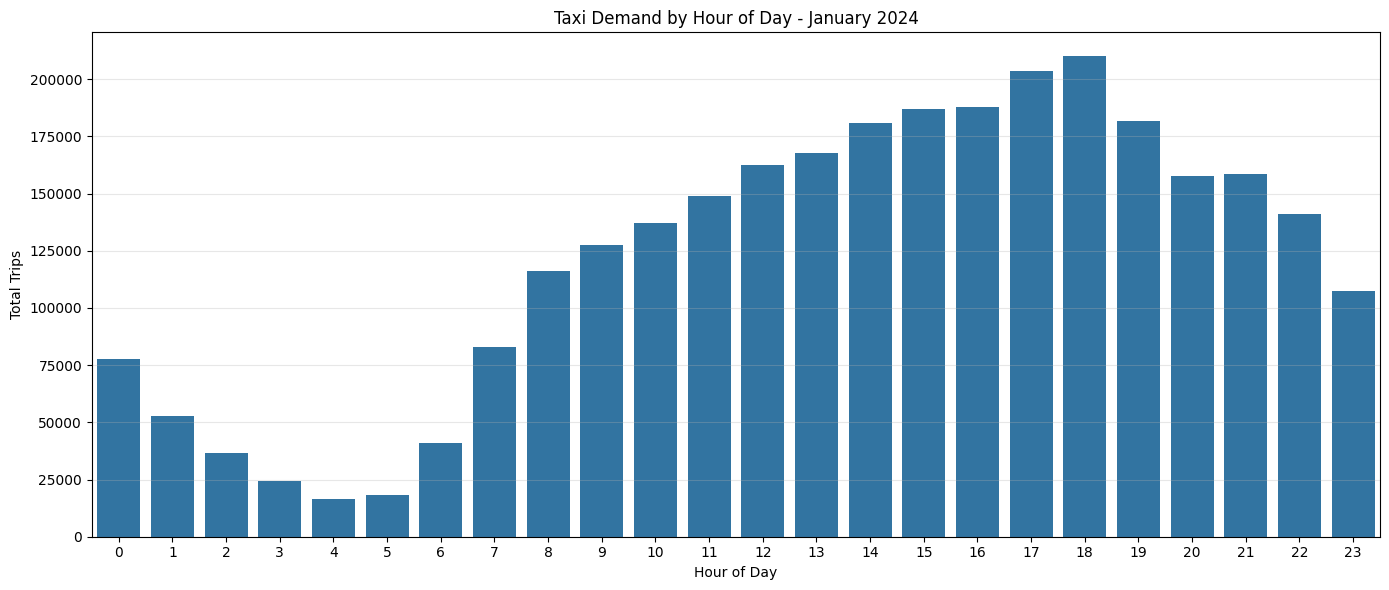

In [43]:
hourly_demand = df_analysis.groupby("pickup_hour").size()
display(hourly_demand)



plt.figure(figsize=(14, 6))
sns.barplot(
    x=hourly_demand.index,
    y=hourly_demand.values
)
plt.title("Taxi Demand by Hour of Day - January 2024")
plt.xlabel("Hour of Day")
plt.ylabel("Total Trips")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Observation
- Hourly demand has a clear daily cycle: it is lowest in the early morning (approximately 3–5 AM), rises from around 6–7 AM, remains elevated through the day, and peaks around 5–6 PM.
- This can inform time-based fleet allocation and forecasting.

#### Average trips per hour per day

pickup_hour
0     2504.258065
1     1698.548387
2     1185.483871
3      781.516129
4      525.096774
5      592.225806
6     1317.741935
7     2673.548387
8     3743.806452
9     4117.677419
10    4426.225806
11    4800.161290
12    5240.516129
13    5411.903226
14    5829.161290
15    6030.774194
16    6057.258065
17    6571.677419
18    6774.580645
19    5858.645161
20    5091.870968
21    5118.903226
22    4552.258065
23    3466.032258
dtype: float64

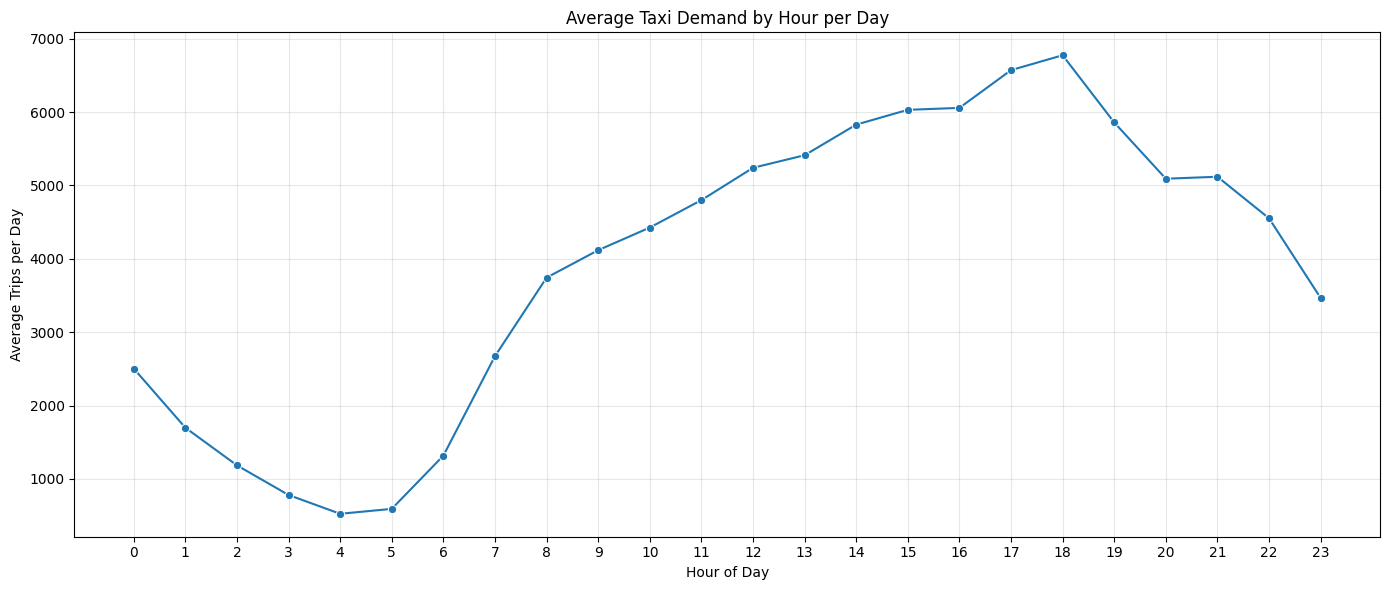

In [44]:
hourly_avg_demand = (
    df_analysis.groupby(["pickup_date", "pickup_hour"])
    .size()
    .groupby(level=1)
    .mean()
)
display(hourly_avg_demand)



plt.figure(figsize=(14, 6))

sns.lineplot(
    x=hourly_avg_demand.index,
    y=hourly_avg_demand.values,
    marker="o"
)

plt.title("Average Taxi Demand by Hour per Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Trips per Day")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Observation
- Average hourly demand is lowest around 4 AM (approximately 500 trips per day), rises from early morning, and peaks around 6 PM (approximately 6,750 trips per average day).
- Demand declines after the evening peak.
- These values are descriptive for this month and should not be assumed to generalize to other months.

#### Hour × Day-of-week heatmap

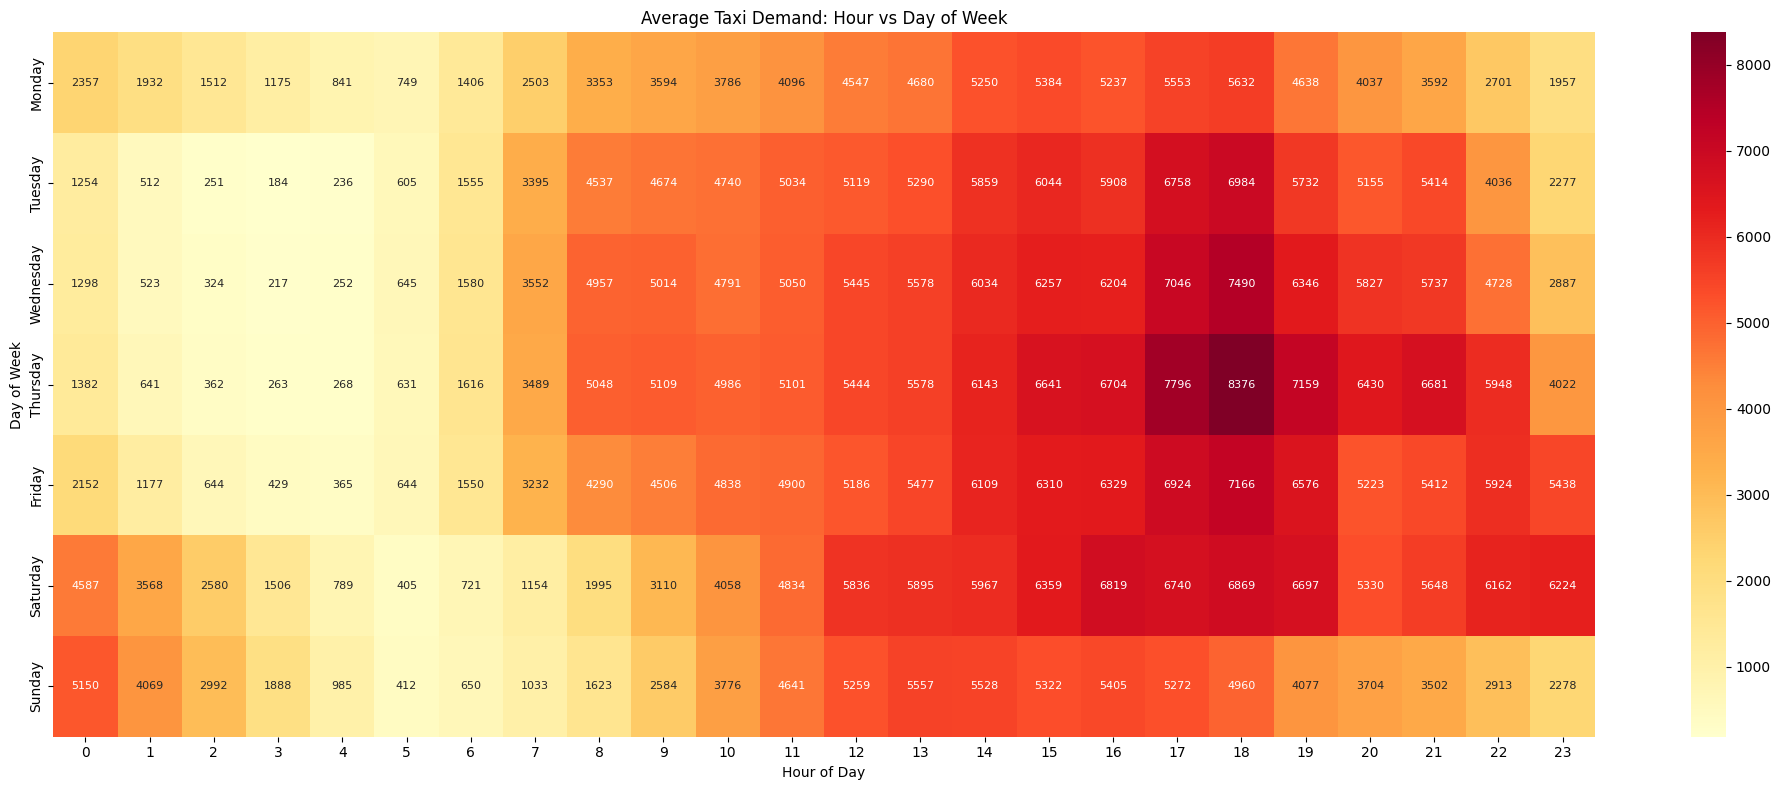

In [45]:
# Build a complete hourly pickup-count series so hours with zero pickups are represented.
# This avoids averaging only those weekday-hour combinations that happened to occur.

hourly_counts = (
    df_analysis
    .set_index("tpep_pickup_datetime")
    .resample("h")
    .size()
)

# Derive weekday and hour from each hourly timestamp.
hourly_counts_df = hourly_counts.rename("trips").to_frame()
hourly_counts_df["day_of_week"] = hourly_counts_df.index.day_name()
hourly_counts_df["hour"] = hourly_counts_df.index.hour

# Average trips for each hour across occurrences of each weekday.
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]
hourly_day_demand = (
    hourly_counts_df
    .groupby(["day_of_week", "hour"])["trips"]
    .mean()
    .unstack("hour")
    .reindex(day_order)
    .reindex(columns=range(24))
)

# Plot average weekday-hour demand.
plt.figure(figsize=(20, 8))
sns.heatmap(
    hourly_day_demand,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f",
    annot_kws={"size": 8}
)
plt.title("Average Taxi Demand: Hour vs Day of Week")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.show()


### Heatmap observations
- Demand is low during early-morning hours for most weekdays.
- Weekday demand rises during the morning and is elevated into the evening.
- Evening demand is strong across most days, with some weekday differences.
- Weekend early-morning patterns differ from weekdays.

**Business implication:** Hour-of-day and day-of-week interactions may be useful forecasting features. These patterns are descriptive; further validation is needed before pricing decisions.

#### Pickup-location demand analysis

PULocationID
161    141697
237    141224
132    141060
236    135286
162    105428
230    104576
186    103243
142    102947
138     88537
239     87622
163     84592
170     82079
68      76751
234     75425
48      75303
141     73105
249     65515
140     65338
79      65140
164     64043
dtype: int64

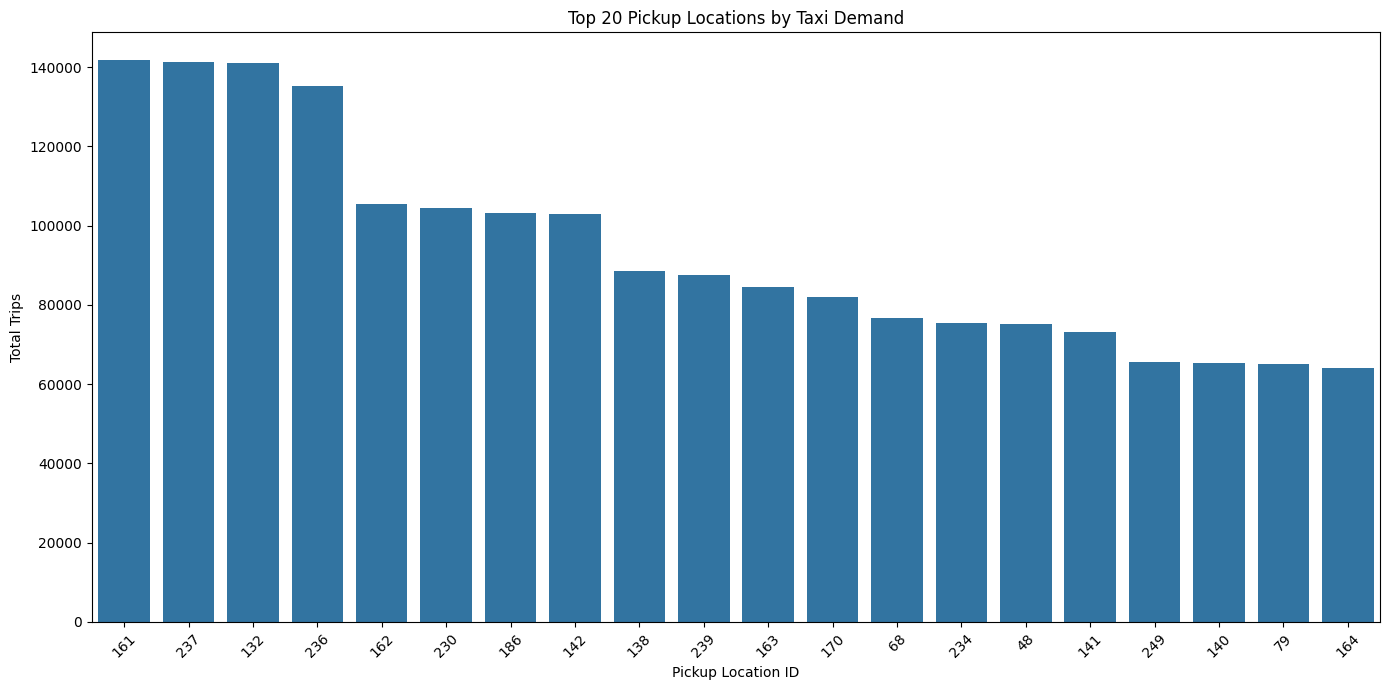

In [46]:
location_demand = df_analysis.groupby("PULocationID").size().sort_values(ascending=False)
display(location_demand.head(20))



plt.figure(figsize=(14, 7))

sns.barplot(
    x=location_demand.head(20).index.astype(str),
    y=location_demand.head(20).values
)

plt.title("Top 20 Pickup Locations by Taxi Demand")
plt.xlabel("Pickup Location ID")
plt.ylabel("Total Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Pickup-location insights
- Pickup demand is concentrated in a small number of zones.
- Pickup Location IDs are categorical identifiers; the numeric magnitude of an ID does not imply demand or rank.
- Location-level demand forecasts may be more actionable than city-wide forecasts for driver positioning and pricing.

#### Demand by Location × Hour

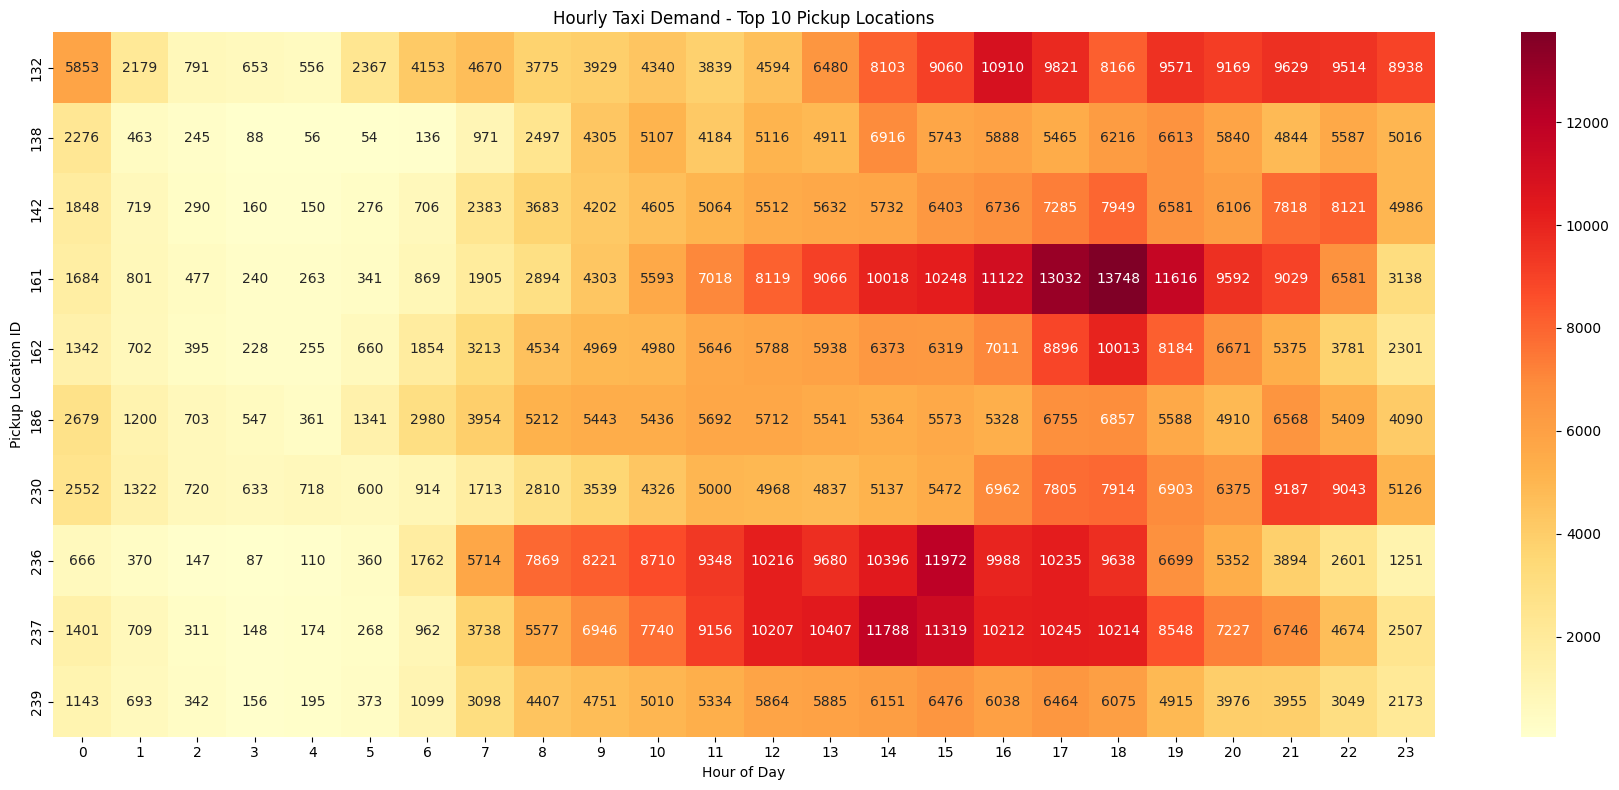

In [47]:
top_10_locations = location_demand.head(10).index

location_hour_demand = (
    df_analysis[df_analysis["PULocationID"].isin(top_10_locations)]
    .groupby(["PULocationID", "pickup_hour"])
    .size()
    .unstack()
)

plt.figure(figsize=(18, 8))

sns.heatmap(
    location_hour_demand,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f"
)

plt.title("Hourly Taxi Demand - Top 10 Pickup Locations")
plt.xlabel("Hour of Day")
plt.ylabel("Pickup Location ID")
plt.tight_layout()
plt.show()

### Business insight
- Demand varies by both pickup location and hour.
- Some locations have strong evening peaks, while others show higher daytime demand.
- A city-wide surge multiplier may not reflect these local differences.

**Preliminary strategy hypothesis:** 
- Evaluate pricing at a **location × time** level.
- This is a hypothesis to test, not a final recommendation;
- supply availability and price elasticity are not observed in this dataset.

## 5. Demand Forecasting

We will build hourly demand time series for selected pickup locations. Before modeling, we must verify that the demand dataset contains valid pickup events and that missing hours are represented as zero demand.

### Creating a Separate Dataset for Demand Forecasting

- The original dataset is reloaded to preserve the raw pickup records before applying fare, trip-distance, or duration-related cleaning.
- A separate demand dataset will be created using only valid pickup timestamps and pickup locations.
- Each valid record will represent one observed pickup event.

**Assumption:** 
Records with valid pickup timestamps and pickup locations represent pickup events, even if other trip-related attributes are missing or suspicious.

This separation prevents fare and trip-quality filters from unintentionally reducing the observed demand used for forecasting.

In [59]:
# Load the original January 2024 NYC Yellow Taxi dataset
df_raw = pd.read_parquet(
    "/Users/tarunraghav/Downloads/RADIX case study/yellow_tripdata_2024-01.parquet"
)

# Display dataset information
print("Original Dataset Shape:", df_raw.shape)


# Create a separate dataset specifically for demand forecasting
df_demand = df_raw.copy()

# Keep only valid pickup timestamp and pickup location
df_demand = df_demand[
    df_demand["tpep_pickup_datetime"].notna() &
    df_demand["PULocationID"].notna()
]

# Restrict pickup events to January 2024
df_demand = df_demand[
    (df_demand["tpep_pickup_datetime"] >= "2024-01-01") &
    (df_demand["tpep_pickup_datetime"] < "2024-02-01")
].copy()

print("Demand dataset shape:", df_demand.shape)
print("Total pickup events:", len(df_demand))
print("Unique pickup locations:", df_demand["PULocationID"].nunique())

Original Dataset Shape: (2964624, 19)
Demand dataset shape: (2964606, 19)
Total pickup events: 2964606
Unique pickup locations: 260


### Hourly Demand Aggregation by Pickup Location
- The cleaned demand dataset is aggregated into hourly pickup counts for each pickup location.
- This transformation converts trip-level records into a time-series dataset suitable for demand forecasting.

**Why hourly aggregation?**
- Taxi demand varies significantly throughout the day.
- Hourly granularity captures rush hours, nighttime demand, and daily patterns.
- Location-level aggregation allows us to forecast demand independently for different areas.

**Important:** Missing hourly combinations will be filled with zero pickups. This ensures that the time series contains a continuous hourly timeline and that absence of recorded pickups is represented explicitly.

In [60]:
# Create hourly timestamp by rounding pickup datetime down to the hour
df_demand["pickup_hour"] = df_demand["tpep_pickup_datetime"].dt.floor("h")

# Aggregate pickup counts by hour and pickup location
hourly_demand = (
    df_demand
    .groupby(["pickup_hour", "PULocationID"])
    .size()
    .reset_index(name="pickup_count")
)

# Display the aggregated dataset
print("Hourly demand dataset shape:", hourly_demand.shape)

hourly_demand.head()

Hourly demand dataset shape: (77530, 3)


,pickup_hour,PULocationID,pickup_count
0,2024-01-01,4,25
1,2024-01-01,7,4
2,2024-01-01,9,1
3,2024-01-01,10,6
4,2024-01-01,12,4


### Creating a Complete Hourly Time Series
- The aggregated dataset currently contains only hour-location combinations where at least one pickup occurred.
- For forecasting, we need a continuous hourly timeline for every pickup location. Therefore, we will create all possible hourly combinations for January 2024 and fill missing pickup counts with zero.

**Assumption:** If a location has no recorded pickups during a particular hour, its demand for that hour is treated as zero.

This creates a complete time series and prevents gaps from affecting forecasting models.

In [50]:
# Generate all hours in January 2024
all_hours = pd.date_range(
    start="2024-01-01 00:00:00",
    end="2024-01-31 23:00:00",
    freq="h"
)

# Get all pickup locations present in the demand dataset
all_locations = df_demand["PULocationID"].unique()

# Create every possible combination of hour and pickup location
complete_index = pd.MultiIndex.from_product(
    [all_hours, all_locations],
    names=["pickup_hour", "PULocationID"]
)

# Reindex the aggregated demand data to include missing combinations
hourly_demand_complete = (
    hourly_demand
    .set_index(["pickup_hour", "PULocationID"])
    .reindex(complete_index, fill_value=0)
    .reset_index()
)

# Display results
print("Complete hourly demand shape:", hourly_demand_complete.shape)
print("Total pickup count before:", hourly_demand["pickup_count"].sum())
print("Total pickup count after:", hourly_demand_complete["pickup_count"].sum())

hourly_demand_complete.head()

Complete hourly demand shape: (193440, 3)
Total pickup count before: 2964606
Total pickup count after: 2964606


,pickup_hour,PULocationID,pickup_count
0,2024-01-01,186,102
1,2024-01-01,140,97
2,2024-01-01,236,165
3,2024-01-01,79,354
4,2024-01-01,211,51


### Selecting High-Demand Pickup Locations
- We will initially focus on the top 10 pickup locations based on total pickup demand during the training period.

Focusing on high-demand locations allows us to:
- Build and evaluate forecasting models on locations with sufficient demand.
- Reduce computational complexity.
- Prioritize locations with potentially greater business impact.

**Methodology:** Location selection will be based only on the training period to avoid using future information from the test period.

The selected locations will be used for forecasting and dynamic pricing simulation.

In [51]:
# Define the training period
train_end = "2024-01-24 23:00:00"

# Calculate demand per location using only the training period
location_demand_train = (
    hourly_demand_complete[
        hourly_demand_complete["pickup_hour"] <= train_end
    ]
    .groupby("PULocationID")["pickup_count"]
    .sum()
    .sort_values(ascending=False)
)

# Select the top 10 locations
top_10_locations = location_demand_train.head(10)

# Display selected locations
print("Top 10 pickup locations based on training-period demand:")
display(top_10_locations)

Top 10 pickup locations based on training-period demand:


PULocationID
132    116669
161    108245
237    107094
236    102723
230     82098
162     80757
142     80458
186     79750
138     69795
239     68582
Name: pickup_count, dtype: int64

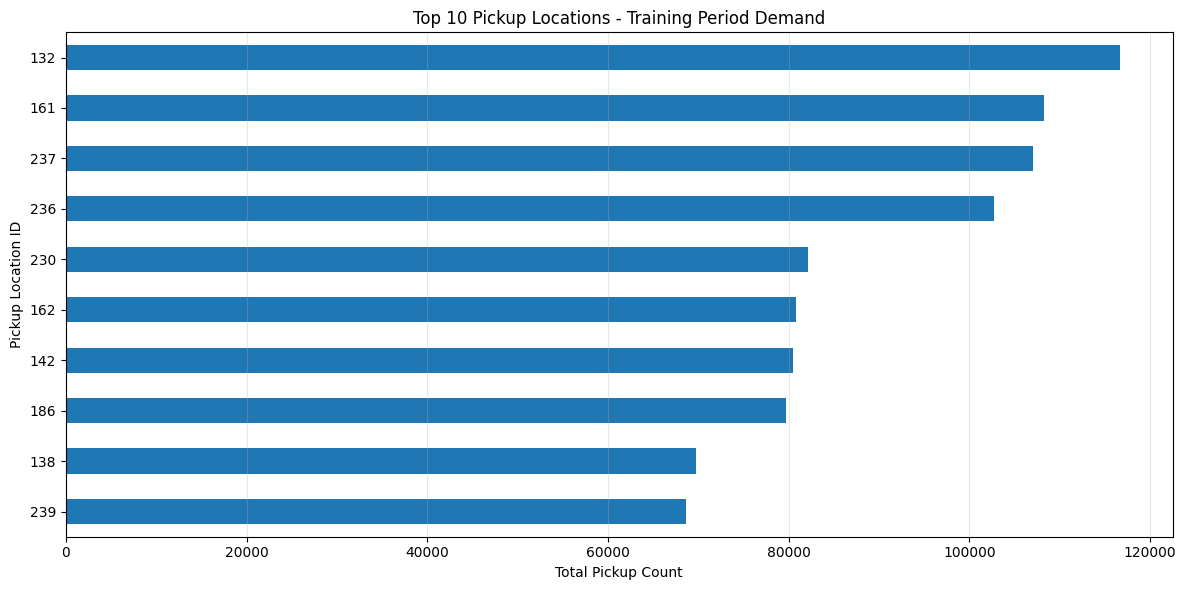

In [52]:
# Plot the top 10 pickup locations
plt.figure(figsize=(12, 6))

top_10_locations.sort_values().plot(kind="barh")

plt.title("Top 10 Pickup Locations - Training Period Demand")
plt.xlabel("Total Pickup Count")
plt.ylabel("Pickup Location ID")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Chronological Train-Test Split

The dataset is split chronologically to simulate a real-world forecasting scenario.
- **Training period:** January 1 to January 24, 2024
- **Testing period:** January 25 to January 31, 2024

The model will learn demand patterns from the training period and forecast demand for the unseen test period.
This approach prevents temporal leakage and provides a realistic evaluation of forecasting performance.

The test period contains 168 hours (7 days), allowing us to evaluate the model across weekdays and weekends.

In [53]:
# Define train and test periods
train_end = pd.Timestamp("2024-01-24 23:00:00")
test_start = pd.Timestamp("2024-01-25 00:00:00")
test_end = pd.Timestamp("2024-01-31 23:00:00")

# Filter only the selected top 10 locations
forecast_data = hourly_demand_complete[
    hourly_demand_complete["PULocationID"].isin(top_10_locations.index)
].copy()

# Chronological train-test split
train_data = forecast_data[
    forecast_data["pickup_hour"] <= train_end
].copy()

test_data = forecast_data[
    (forecast_data["pickup_hour"] >= test_start) &
    (forecast_data["pickup_hour"] <= test_end)
].copy()

# Validation
print("Train period:", train_data["pickup_hour"].min(), "to", train_data["pickup_hour"].max())
print("Test period:", test_data["pickup_hour"].min(), "to", test_data["pickup_hour"].max())

print("\nTrain shape:", train_data.shape)
print("Test shape:", test_data.shape)

print("\nTrain hours:", train_data["pickup_hour"].nunique())
print("Test hours:", test_data["pickup_hour"].nunique())
print("Number of locations:", forecast_data["PULocationID"].nunique())

Train period: 2024-01-01 00:00:00 to 2024-01-24 23:00:00
Test period: 2024-01-25 00:00:00 to 2024-01-31 23:00:00

Train shape: (5760, 3)
Test shape: (1680, 3)

Train hours: 576
Test hours: 168
Number of locations: 10


### Model Building

### Weekly Seasonal Naive Forecasting — Baseline Model
- A weekly seasonal naive model is used as the initial forecasting benchmark.
- The model predicts demand for each hour using the observed demand from the same hour one week earlier.

**Formula:**
\[
\hat{y}_{t}=y_{t-168}
\]

where:
- \(y_t\) = actual demand at time \(t\)
- \(\hat{y}_t\) = forecasted demand
- 168 = number of hours in one week

This baseline captures recurring weekly patterns without requiring model training.

The baseline will be evaluated using:
- **MAE:** Average absolute forecasting error.
- **RMSE:** Penalizes larger forecasting errors more heavily.
- **WAPE:** Total absolute error relative to total actual demand.

The baseline provides a benchmark against which more advanced forecasting models will be compared.

In [55]:
# Create baseline predictions directly using the previous week's timestamp

baseline_test = test_data.copy()

baseline_test["baseline_hour"] = (
    baseline_test["pickup_hour"] - pd.Timedelta(hours=168)
)

# Create lookup table
previous_week_data = forecast_data[
    ["pickup_hour", "PULocationID", "pickup_count"]
].rename(
    columns={
        "pickup_hour": "baseline_hour",
        "pickup_count": "baseline_prediction"
    }
)

# Merge baseline predictions
baseline_test = baseline_test.merge(
    previous_week_data,
    on=["baseline_hour", "PULocationID"],
    how="left"
)

# Evaluate
actual = baseline_test["pickup_count"]
predicted = baseline_test["baseline_prediction"]

print(f"MAE: {mean_absolute_error(actual, predicted):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(actual, predicted)):.2f}")
print(f"WAPE: {np.sum(np.abs(actual - predicted)) / np.sum(actual) * 100:.2f}%")

MAE: 23.61
RMSE: 37.65
WAPE: 14.62%


### Day-of-Week and Hour-of-Day Average Forecasting
- This model predicts hourly pickup demand using historical average demand for the corresponding day of the week and hour of the day, separately for each pickup location.
- For example, demand for Mondays at 6 PM is estimated using historical Monday 6 PM observations from the training period.

**Features used:**
- Pickup location
- Day of week
- Hour of day

**Why this model?**
- Captures recurring weekly demand patterns.
- Learns average demand instead of relying on a single previous week.
- Simple, interpretable, and computationally efficient.
- Provides a useful benchmark before introducing machine learning models.

The model is trained exclusively on the training dataset and evaluated on the same test period used for the baseline.

In [66]:
# Create copies to avoid modifying original train/test datasets
train_model = train_data.copy()
test_model = test_data.copy()

# Extract time-based features
train_model["day_of_week"] = train_model["pickup_hour"].dt.dayofweek
train_model["hour"] = train_model["pickup_hour"].dt.hour

test_model["day_of_week"] = test_model["pickup_hour"].dt.dayofweek
test_model["hour"] = test_model["pickup_hour"].dt.hour

# Display sample
train_model.head()

,pickup_hour,PULocationID,pickup_count,day_of_week,hour
0,2024-01-01,186,102,0,0
2,2024-01-01,236,165,0,0
6,2024-01-01,138,59,0,0
8,2024-01-01,161,254,0,0
14,2024-01-01,132,150,0,0


In [57]:
# Calculate average demand for each location-day-hour combination
pattern_model = (
    train_model
    .groupby(["PULocationID", "day_of_week", "hour"])["pickup_count"]
    .mean()
    .reset_index(name="predicted_demand")
)

print("Learned demand patterns:", pattern_model.shape)

pattern_model.head()

Learned demand patterns: (1680, 4)


,PULocationID,day_of_week,hour,predicted_demand
0,132,0,0,207.25
1,132,0,1,82.50
2,132,0,2,28.50
3,132,0,3,16.75
4,132,0,4,21.75


In [58]:
# Merge learned patterns into the test dataset
pattern_predictions = test_model.merge(
    pattern_model,
    on=["PULocationID", "day_of_week", "hour"],
    how="left"
)

# Actual vs predicted
actual = pattern_predictions["pickup_count"]
predicted = pattern_predictions["predicted_demand"]

# Evaluation metrics
mae_pattern = mean_absolute_error(actual, predicted)
rmse_pattern = np.sqrt(mean_squared_error(actual, predicted))
wape_pattern = np.sum(np.abs(actual - predicted)) / np.sum(actual) * 100

print("Day-of-Week + Hour Pattern Model")
print("--------------------------------")
print(f"MAE  : {mae_pattern:.2f}")
print(f"RMSE : {rmse_pattern:.2f}")
print(f"WAPE : {wape_pattern:.2f}%")

Day-of-Week + Hour Pattern Model
--------------------------------
MAE  : 27.23
RMSE : 40.83
WAPE : 16.86%


**Observations**
- The pattern model's WAPE increased from 14.62% to 16.86%.
- That means it is approximately **2.24 percentage points worse**.
  
**Why might this happen?**
- Our training data has only around 3–4 examples for each location × weekday × hour combination.
- For example, Location 132, Monday, 6 PM might have only 3–4 historical observations. Averaging those can lose information about recent demand changes.
- Meanwhile, the weekly naive model directly uses the previous week's corresponding hour, preserving more recent patterns.

> **Note:** This is an important real-world ML lesson: a more sophisticated model isn't automatically better.

#### Location-Level Model Performance Analysis

Overall forecasting metrics can hide differences in model performance across locations.
We will compare the Weekly Seasonal Naive baseline and the Day-of-Week + Hour Pattern model separately for each pickup location.

This analysis helps identify:
- Locations where the pattern model performs better.
- Locations where the baseline performs better.
- Whether model performance varies significantly across locations.

This can help guide model selection and future improvements.

In [67]:
# Align both model predictions by timestamp and location
baseline_compare = baseline_test[
    ["pickup_hour", "PULocationID", "pickup_count", "baseline_prediction"]
].copy()

pattern_compare = pattern_predictions[
    ["pickup_hour", "PULocationID", "pickup_count", "predicted_demand"]
].copy()

# Merge predictions for fair comparison
comparison = baseline_compare.merge(
    pattern_compare,
    on=["pickup_hour", "PULocationID", "pickup_count"],
    how="inner"
)

# Calculate location-level metrics
location_metrics = []
for location in comparison["PULocationID"].unique():
    loc_data = comparison[
        comparison["PULocationID"] == location
    ]

    actual = loc_data["pickup_count"]

    baseline_pred = loc_data["baseline_prediction"]
    pattern_pred = loc_data["predicted_demand"]

    baseline_wape = (
        np.sum(np.abs(actual - baseline_pred)) /
        np.sum(actual)
    ) * 100

    pattern_wape = (
        np.sum(np.abs(actual - pattern_pred)) /
        np.sum(actual)
    ) * 100

    location_metrics.append({
        "PULocationID": location,
        "Baseline_WAPE": baseline_wape,
        "Pattern_WAPE": pattern_wape,
        "Improvement": baseline_wape - pattern_wape
    })

location_metrics = pd.DataFrame(location_metrics)

location_metrics.sort_values(
    "Improvement",
    ascending=False
)

,PULocationID,Baseline_WAPE,Pattern_WAPE,Improvement
0,186,19.840949,17.134937,2.706012
2,138,20.977958,19.265265,1.712693
8,142,21.234442,20.911650,0.322792
9,230,14.624783,14.926112,-0.301329
6,239,13.342047,15.568654,-2.226607
7,162,11.760401,14.549307,-2.788906
3,161,11.722121,15.175496,-3.453375
4,132,17.689265,22.331210,-4.641945
5,237,11.262741,15.934490,-4.671749
1,236,9.359533,14.436442,-5.076909


> **Positive improvement means the pattern model is better.**

**Key takeaway**
- Location 236 is the strongest location for our weekly baseline: WAPE 9.36%.
- The pattern model helps Locations 186, 138, 142.
- The baseline is substantially better for Locations 132, 237, 236, 161, 162, and 239.
- Therefore, a single model may not be best for every location.

**This is an important business insight: forecasting performance is location-dependent.**

- Now since its a location dependent, we will move to our global ML models such as Randomforest & Xgboost

#### Random Forest Model

## Feature Engineering for Random Forest Forecasting
- Random Forest requires input features that help explain demand variation.
- We will create the following features for each pickup location:

**Time-based features**
- Hour of day
- Day of week
- Weekend indicator

**Lag features**
- Demand 1 hour ago (`lag_1`)
- Demand 24 hours ago (`lag_24`)
- Demand 168 hours ago (`lag_168`)

**Rolling demand features**
- Average demand over the previous 24 hours
- Average demand over the previous 168 hours

Lag and rolling features are calculated separately for each pickup location.

**Leakage prevention:** Lag features use historical observations only. Rolling averages are shifted by one hour so the current hour's actual demand is not included.

**Evaluation strategy:** This model will initially be evaluated using rolling one-hour-ahead predictions, where actual demand from the previous hour becomes available before the next prediction. This differs from forecasting all 24 future hours simultaneously without receiving new actual observations.

In [68]:
# Work with the complete hourly dataset for the selected locations
rf_data = forecast_data.copy()

# Sort data chronologically within each pickup location
rf_data = rf_data.sort_values(
    ["PULocationID", "pickup_hour"]
).copy()

# Time-based features
rf_data["hour"] = rf_data["pickup_hour"].dt.hour
rf_data["day_of_week"] = rf_data["pickup_hour"].dt.dayofweek
rf_data["is_weekend"] = (
    rf_data["day_of_week"] >= 5
).astype(int)

# Lag features: historical demand
rf_data["lag_1"] = (
    rf_data.groupby("PULocationID")["pickup_count"].shift(1)
)

rf_data["lag_24"] = (
    rf_data.groupby("PULocationID")["pickup_count"].shift(24)
)

rf_data["lag_168"] = (
    rf_data.groupby("PULocationID")["pickup_count"].shift(168)
)

# Rolling averages based only on previous observations
rf_data["rolling_mean_24"] = (
    rf_data.groupby("PULocationID")["pickup_count"]
    .transform(lambda x: x.shift(1).rolling(window=24).mean())
)

rf_data["rolling_mean_168"] = (
    rf_data.groupby("PULocationID")["pickup_count"]
    .transform(lambda x: x.shift(1).rolling(window=168).mean())
)

# Display engineered features
rf_data.head(10)

,pickup_hour,PULocationID,pickup_count,hour,day_of_week,is_weekend,lag_1,lag_24,lag_168,rolling_mean_24,rolling_mean_168
14,2024-01-01 00:00:00,132,150,0,0,0,NaN,NaN,NaN,NaN,NaN
274,2024-01-01 01:00:00,132,68,1,0,0,150.0,NaN,NaN,NaN,NaN
534,2024-01-01 02:00:00,132,21,2,0,0,68.0,NaN,NaN,NaN,NaN
794,2024-01-01 03:00:00,132,18,3,0,0,21.0,NaN,NaN,NaN,NaN
1054,2024-01-01 04:00:00,132,26,4,0,0,18.0,NaN,NaN,NaN,NaN
1314,2024-01-01 05:00:00,132,58,5,0,0,26.0,NaN,NaN,NaN,NaN
1574,2024-01-01 06:00:00,132,203,6,0,0,58.0,NaN,NaN,NaN,NaN
1834,2024-01-01 07:00:00,132,217,7,0,0,203.0,NaN,NaN,NaN,NaN
2094,2024-01-01 08:00:00,132,141,8,0,0,217.0,NaN,NaN,NaN,NaN
2354,2024-01-01 09:00:00,132,157,9,0,0,141.0,NaN,NaN,NaN,NaN


### Preparing Data for Random Forest
- After creating lag and rolling features, the initial observations contain missing feature values because sufficient historical data is not available.
- We will remove rows where the required lag or rolling features are missing.

The train-test split remains chronological:
- Training: January 1–24, 2024
- Testing: January 25–31, 2024

All features are derived from historical demand. The target variable is `pickup_count`.
The model will be evaluated on the same test period as the previously developed forecasting models.

In [69]:
# Define features and target
features = [
    "PULocationID",
    "hour",
    "day_of_week",
    "is_weekend",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_24",
    "rolling_mean_168"
]

target = "pickup_count"

# Remove rows with missing lag/rolling features
rf_data_clean = rf_data.dropna(subset=features).copy()

# Chronological split
rf_train = rf_data_clean[
    rf_data_clean["pickup_hour"] <= train_end
].copy()

rf_test = rf_data_clean[
    (rf_data_clean["pickup_hour"] >= test_start) &
    (rf_data_clean["pickup_hour"] <= test_end)
].copy()

# Separate X and y
X_train = rf_train[features]
y_train = rf_train[target]

X_test = rf_test[features]
y_test = rf_test[target]

# Validation
print("RF Train shape:", X_train.shape)
print("RF Test shape:", X_test.shape)

print("\nTrain period:", rf_train["pickup_hour"].min(), "to", rf_train["pickup_hour"].max())
print("Test period:", rf_test["pickup_hour"].min(), "to", rf_test["pickup_hour"].max())

RF Train shape: (4080, 9)
RF Test shape: (1680, 9)

Train period: 2024-01-08 00:00:00 to 2024-01-24 23:00:00
Test period: 2024-01-25 00:00:00 to 2024-01-31 23:00:00


**One subtle point:** our test features are built using the actual historical demand from the preceding hours. This is a rolling one-hour-ahead evaluation, where each new hour's actual demand becomes available before predicting the next hour. We'll keep that evaluation assumption explicit.

### Random Forest Regression Model
- Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees.
- Each tree learns relationships between input features and pickup demand.
- The final prediction is obtained by averaging predictions from all trees.

**Why Random Forest?**
- Captures nonlinear relationships.
- Handles interactions between features.
- Requires minimal feature scaling.
- Reduces overfitting compared with a single decision tree.
- Can provide feature importance for business interpretation.

**Initial model configuration:**
- 300 decision trees
- Maximum depth: unrestricted initially
- Minimum samples per leaf: 2
- Random seed: 42

These parameters are used as an initial baseline configuration and will not be treated as optimized hyperparameters.

In [70]:
# Import Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

# Initialize model
rf_model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model training completed successfully!")

Random Forest model training completed successfully!


In [71]:
# Generate predictions
rf_predictions = rf_model.predict(X_test)

# Evaluate model
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_wape = (
    np.sum(np.abs(y_test - rf_predictions)) /
    np.sum(y_test)
) * 100

print("Random Forest Model Performance")
print("------------------------------")
print(f"MAE  : {rf_mae:.2f}")
print(f"RMSE : {rf_rmse:.2f}")
print(f"WAPE : {rf_wape:.2f}%")

Random Forest Model Performance
------------------------------
MAE  : 22.55
RMSE : 34.59
WAPE : 13.96%


#### Forecasting Model Comparison
- The forecasting models are evaluated using the same test period and performance metrics.
- The comparison helps determine whether additional model complexity provides measurable value over simple forecasting approaches.

Metrics:
- MAE
- RMSE
- WAPE

> - Lower values indicate better forecasting performance.
> - Random Forest currently performs best among the evaluated models.

,Model,MAE,RMSE,WAPE
0,Weekly Seasonal Naive,23.610000,37.65000,14.620000
1,Day-Hour Pattern,27.230000,40.83000,16.860000
2,Random Forest,22.553327,34.59135,13.963056


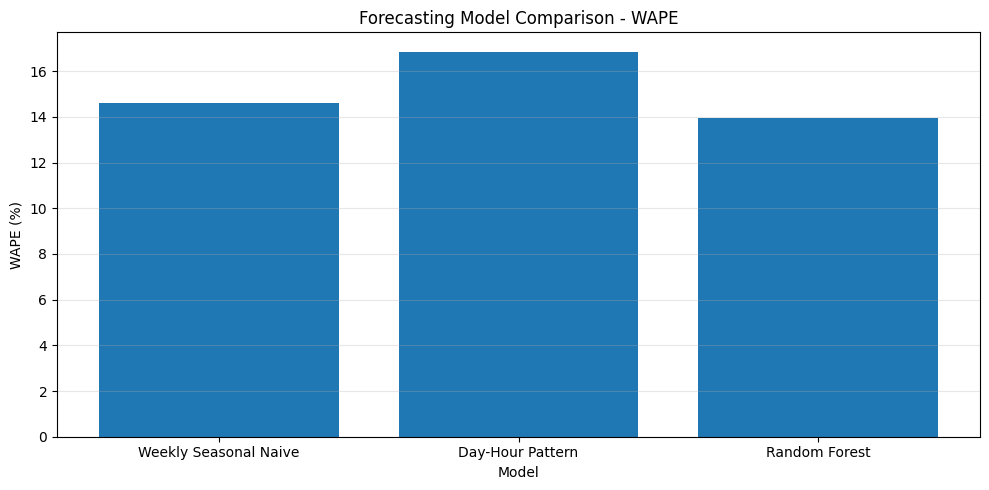

In [72]:
# Create model comparison dataframe
model_comparison = pd.DataFrame({
    "Model": [
        "Weekly Seasonal Naive",
        "Day-Hour Pattern",
        "Random Forest"
    ],
    "MAE": [23.61, 27.23, rf_mae],
    "RMSE": [37.65, 40.83, rf_rmse],
    "WAPE": [14.62, 16.86, rf_wape]
})

display(model_comparison)

# Visualize WAPE
plt.figure(figsize=(10, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["WAPE"]
)

plt.title("Forecasting Model Comparison - WAPE")
plt.ylabel("WAPE (%)")
plt.xlabel("Model")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

,Feature,Importance
4,lag_1,0.722630
6,lag_168,0.138501
5,lag_24,0.071915
1,hour,0.028688
7,rolling_mean_24,0.012666
8,rolling_mean_168,0.011388
2,day_of_week,0.008092
0,PULocationID,0.005653
3,is_weekend,0.000468


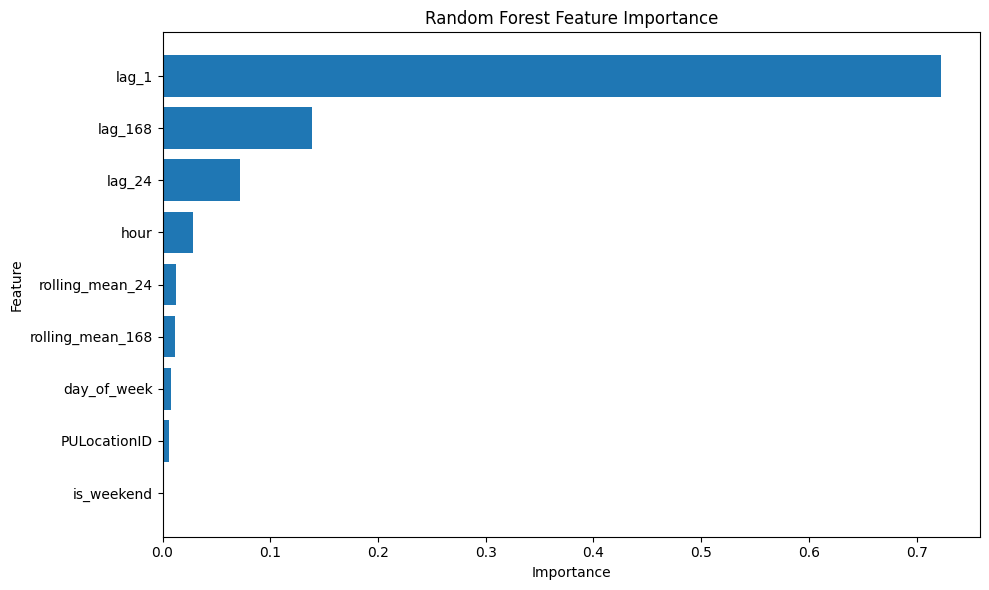

In [74]:
# Extract feature importance: Which feature contribute more
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

display(feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### Model Comparison - Observations

- Random Forest performed the best among the three evaluated models, achieving the lowest MAE (22.55), RMSE (34.59), and WAPE (13.96%).
- Compared to the Weekly Seasonal Naive baseline, Random Forest reduced MAE by approximately 4.5%, RMSE by 8.1%, and WAPE by 0.66 percentage points.
- The Day-Hour Pattern model performed worse than both other models, indicating that averaging demand based on weekday and hour alone does not capture the demand variability effectively.
- The Weekly Seasonal Naive model provides a strong baseline, highlighting the importance of weekly recurring demand patterns.
- Random Forest provides a modest but consistent improvement over the baseline by incorporating recent demand, daily/weekly lags, and temporal features.

**Conclusion:** Random Forest is selected as the best-performing model so far. However, its improvement over the baseline is relatively modest, suggesting that additional features and forecasting strategies may further improve prediction accuracy.

### Random Forest Feature Importance - Observations

- `lag_1` is the most important feature, contributing approximately 72.26% of the model's total feature importance. This indicates that demand during the previous hour is the strongest predictor of current demand.
- `lag_168` (previous week's demand at the same hour) contributes approximately 13.85%, highlighting the importance of weekly seasonality.
- `lag_24` contributes approximately 7.19%, indicating that demand from the same hour on the previous day also provides useful predictive information.
- Time-based features such as `hour`, `day_of_week`, and `is_weekend` contribute relatively less compared to historical demand features.
- Rolling averages provide additional information about recent and weekly demand trends, although their individual contribution is relatively small.

**Conclusion:** Taxi demand exhibits strong temporal dependency, particularly on recent demand. The model relies heavily on lag-based features, suggesting that historical demand patterns are highly informative for forecasting.

In [75]:
# Calculate location-wise forecasting performance

rf_test_results = rf_test.copy()

rf_test_results["actual"] = y_test.values
rf_test_results["predicted"] = rf_predictions

location_metrics = (
    rf_test_results
    .groupby("PULocationID")
    .apply(lambda x: pd.Series({
        "MAE": np.mean(np.abs(x["actual"] - x["predicted"])),
        "RMSE": np.sqrt(np.mean((x["actual"] - x["predicted"])**2)),
        "WAPE": (
            np.sum(np.abs(x["actual"] - x["predicted"])) /
            np.sum(x["actual"])
        ) * 100
    }))
    .reset_index()
    .sort_values("WAPE")
)

display(location_metrics)

/var/folders/tm/nqj5tscx42j994kv275tnb3h0000gn/T/ipykernel_62627/1070030485.py:9: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  rf_test_results


,PULocationID,MAE,RMSE,WAPE
7,236,19.775781,28.145411,9.846570
3,161,20.927531,33.030340,9.981334
8,237,24.089417,33.991133,11.363890
9,239,15.019169,21.561085,12.684599
4,162,19.757261,27.975315,12.785901
6,230,19.421479,29.684710,13.468210
0,132,29.894595,39.113344,17.578286
5,186,27.286448,41.719216,18.505261
2,142,26.484884,49.868164,18.836087
1,138,22.876708,32.267458,19.474471


### Location-wise Random Forest Performance - Observations

- Model performance varies significantly across pickup locations, indicating that demand patterns are not uniform across NYC.
- Location 236 achieved the best performance with a WAPE of approximately 9.85%, followed by Location 161 (9.98%) and Location 237 (11.36%).
- Locations 236 and 161 show relatively predictable demand patterns, allowing the model to forecast demand with higher accuracy.
- Locations 138 (19.47%), 142 (18.84%), and 186 (18.51%) have comparatively higher forecasting errors, suggesting more volatile or complex demand patterns.
- Location 132 also shows relatively high error (17.58%), despite being among the highest-demand locations.
- The results highlight that forecasting accuracy depends not only on overall demand volume but also on the demand variability and behavioral patterns of individual locations.

**Conclusion:** Random Forest performs well for several locations, particularly Locations 236 and 161. However, locations with higher forecast errors may require location-specific modeling, additional features, or alternative forecasting approaches.

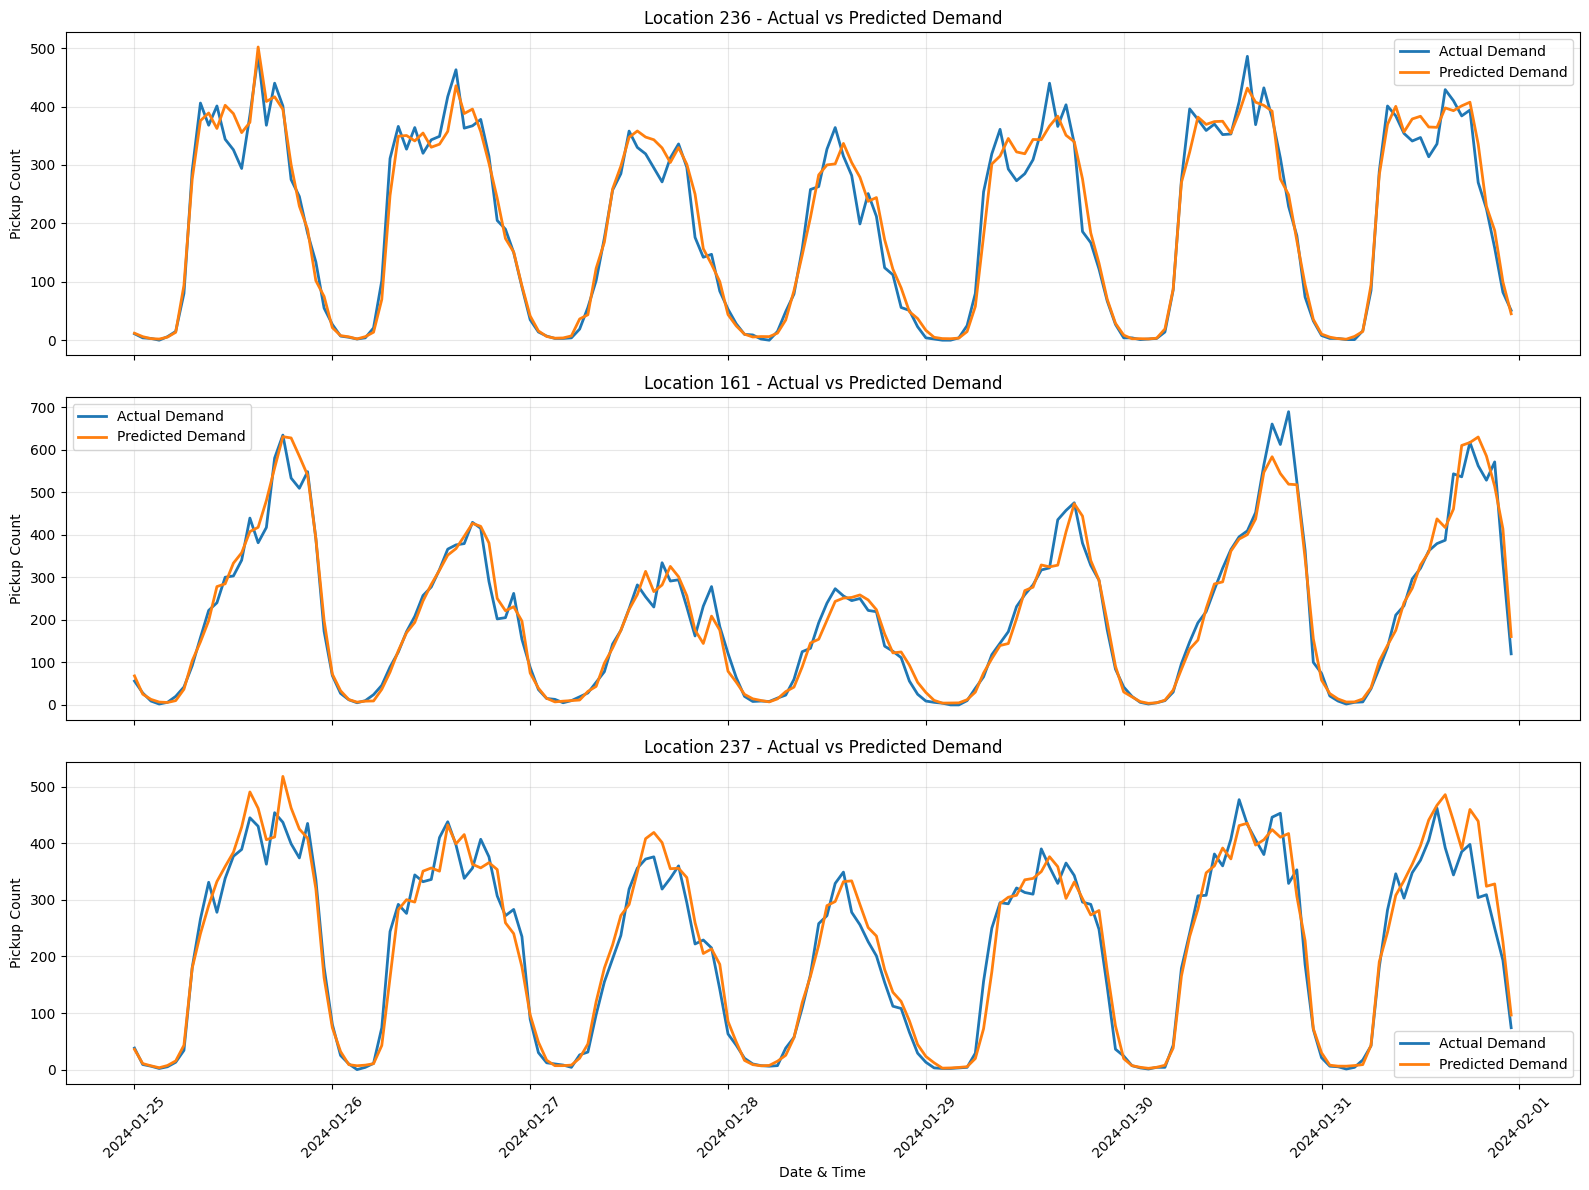

In [76]:
# Visualize Actual vs Predicted Demand for the top 3 best-performing locations

best_locations = [236, 161, 237]

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

for ax, location in zip(axes, best_locations):

    location_data = (
        rf_test_results[rf_test_results["PULocationID"] == location]
        .sort_values("pickup_hour")
    )

    ax.plot(
        location_data["pickup_hour"],
        location_data["actual"],
        label="Actual Demand",
        linewidth=2
    )

    ax.plot(
        location_data["pickup_hour"],
        location_data["predicted"],
        label="Predicted Demand",
        linewidth=2
    )

    ax.set_title(f"Location {location} - Actual vs Predicted Demand")
    ax.set_ylabel("Pickup Count")
    ax.legend()
    ax.grid(alpha=0.3)

plt.xlabel("Date & Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Actual vs Predicted Demand - Observations
- The predicted demand closely follows the actual demand trends across all three selected locations.
- The Random Forest model successfully captures recurring daily demand patterns, including peak and low-demand periods.
- Location 236 shows strong alignment between actual and predicted values, consistent with its low WAPE.
- Location 161 captures the overall demand pattern effectively, although some sharp demand spikes are underestimated.
- Location 237 follows the general demand trend but exhibits relatively larger deviations during certain peak-demand periods.
- The model tends to smooth sudden fluctuations and may not fully capture unexpected demand spikes.

**Conclusion:** The Random Forest model demonstrates good forecasting capability for hourly taxi demand by capturing overall trends and recurring patterns. However, prediction errors during sudden demand spikes indicate scope for improvement through additional features and more advanced forecasting techniques.

## Next 24 Hours Demand Forecast

In [77]:
# Forecast demand for the next 24 hours using Random Forest
# Recursive forecasting: predicted values are used as inputs for future predictions

forecast_horizon = 24

forecast_start = hourly_demand_complete["pickup_hour"].max() + pd.Timedelta(hours=1)

future_hours = pd.date_range(
    start=forecast_start,
    periods=forecast_horizon,
    freq="h"
)

future_forecasts = []

for location in top_10_locations.index:

    # Extract historical hourly demand for this location
    history = (
        hourly_demand_complete[
            hourly_demand_complete["PULocationID"] == location
        ]
        .sort_values("pickup_hour")["pickup_count"]
        .tolist()
    )

    # Generate forecasts recursively
    for future_time in future_hours:

        features_row = {
            "PULocationID": location,
            "hour": future_time.hour,
            "day_of_week": future_time.dayofweek,
            "is_weekend": int(future_time.dayofweek >= 5),
            "lag_1": history[-1],
            "lag_24": history[-24],
            "lag_168": history[-168],
            "rolling_mean_24": np.mean(history[-24:]),
            "rolling_mean_168": np.mean(history[-168:])
        }

        # Make prediction
        prediction = rf_model.predict(
            pd.DataFrame([features_row])[features]
        )[0]

        # Demand cannot be negative
        prediction = max(0, prediction)

        # Store prediction
        future_forecasts.append({
            "pickup_hour": future_time,
            "PULocationID": location,
            "predicted_demand": prediction
        })

        # Append prediction to history for next recursive forecast
        history.append(prediction)


future_forecast_df = pd.DataFrame(future_forecasts)

display(future_forecast_df.head(10))

print("Forecast start:", future_forecast_df["pickup_hour"].min())
print("Forecast end:", future_forecast_df["pickup_hour"].max())
print("Total forecast rows:", future_forecast_df.shape[0])

,pickup_hour,PULocationID,predicted_demand
0,2024-02-01 00:00:00,132,169.376036
1,2024-02-01 01:00:00,132,48.840162
2,2024-02-01 02:00:00,132,17.406361
3,2024-02-01 03:00:00,132,8.154667
4,2024-02-01 04:00:00,132,7.409960
5,2024-02-01 05:00:00,132,64.152894
6,2024-02-01 06:00:00,132,110.624816
7,2024-02-01 07:00:00,132,120.924926
8,2024-02-01 08:00:00,132,111.218748
9,2024-02-01 09:00:00,132,109.538468


Forecast start: 2024-02-01 00:00:00
Forecast end: 2024-02-01 23:00:00
Total forecast rows: 240


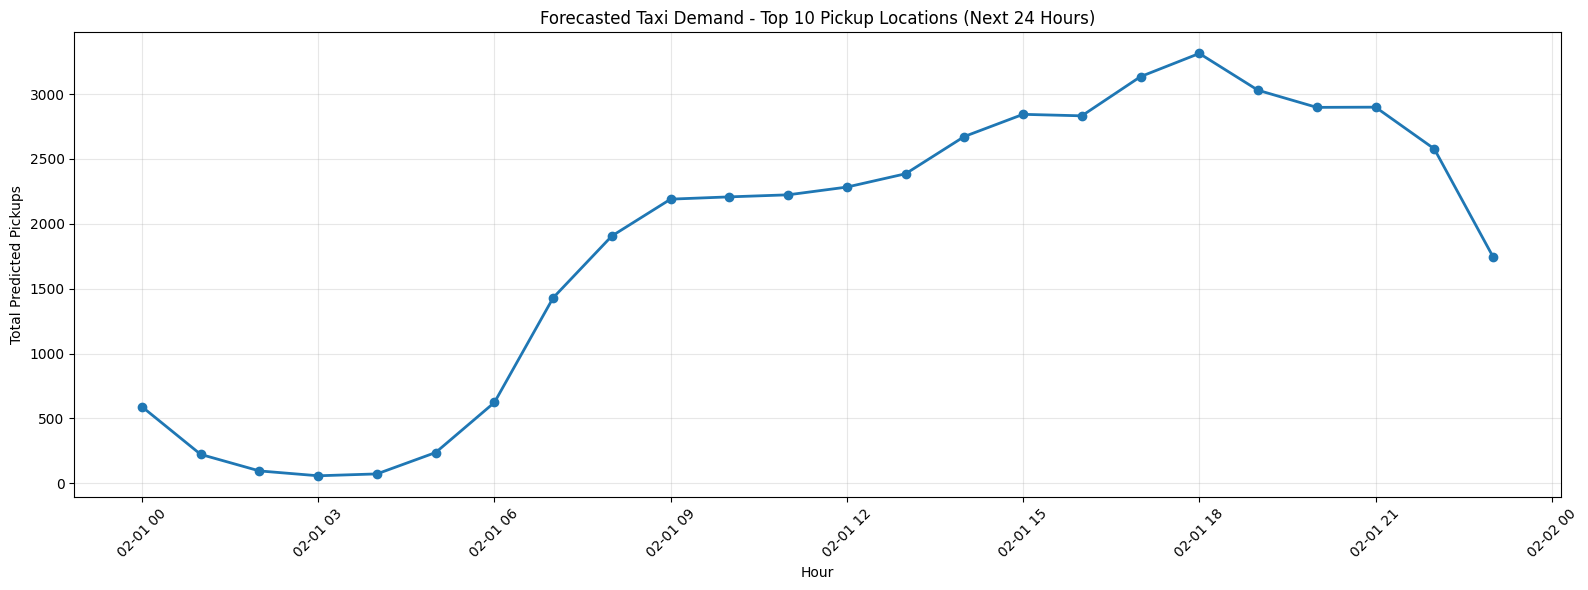

In [78]:
# Aggregate forecasted demand across the selected 10 locations
hourly_total_forecast = (
    future_forecast_df
    .groupby("pickup_hour")["predicted_demand"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(16, 6))

plt.plot(
    hourly_total_forecast["pickup_hour"],
    hourly_total_forecast["predicted_demand"],
    marker="o",
    linewidth=2
)

plt.title("Forecasted Taxi Demand - Top 10 Pickup Locations (Next 24 Hours)")
plt.xlabel("Hour")
plt.ylabel("Total Predicted Pickups")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 24-Hour Demand Forecast - Observations
- The forecast indicates a clear daily demand pattern across the selected 10 pickup locations.
- Demand is lowest during the early morning hours, particularly around 3 AM–4 AM.
- Taxi demand begins increasing from approximately 5 AM–6 AM, with a sharp rise during the morning hours.
- Demand reaches relatively high levels by 9 AM and continues increasing gradually throughout the day.
- The highest forecasted demand occurs around 6 PM (18:00), with approximately 3,300 predicted pickups across the selected locations.
- Demand remains relatively high during the evening period before declining after 9 PM.
- The forecast highlights substantial differences between peak and off-peak demand periods, which can support fleet allocation and operational planning.

**Business Implication:** Taxi fleet availability should be increased during morning and evening peak periods, while lower-demand early morning hours may provide opportunities for fleet optimization and driver scheduling.

### Location-wise Forecast Visualization

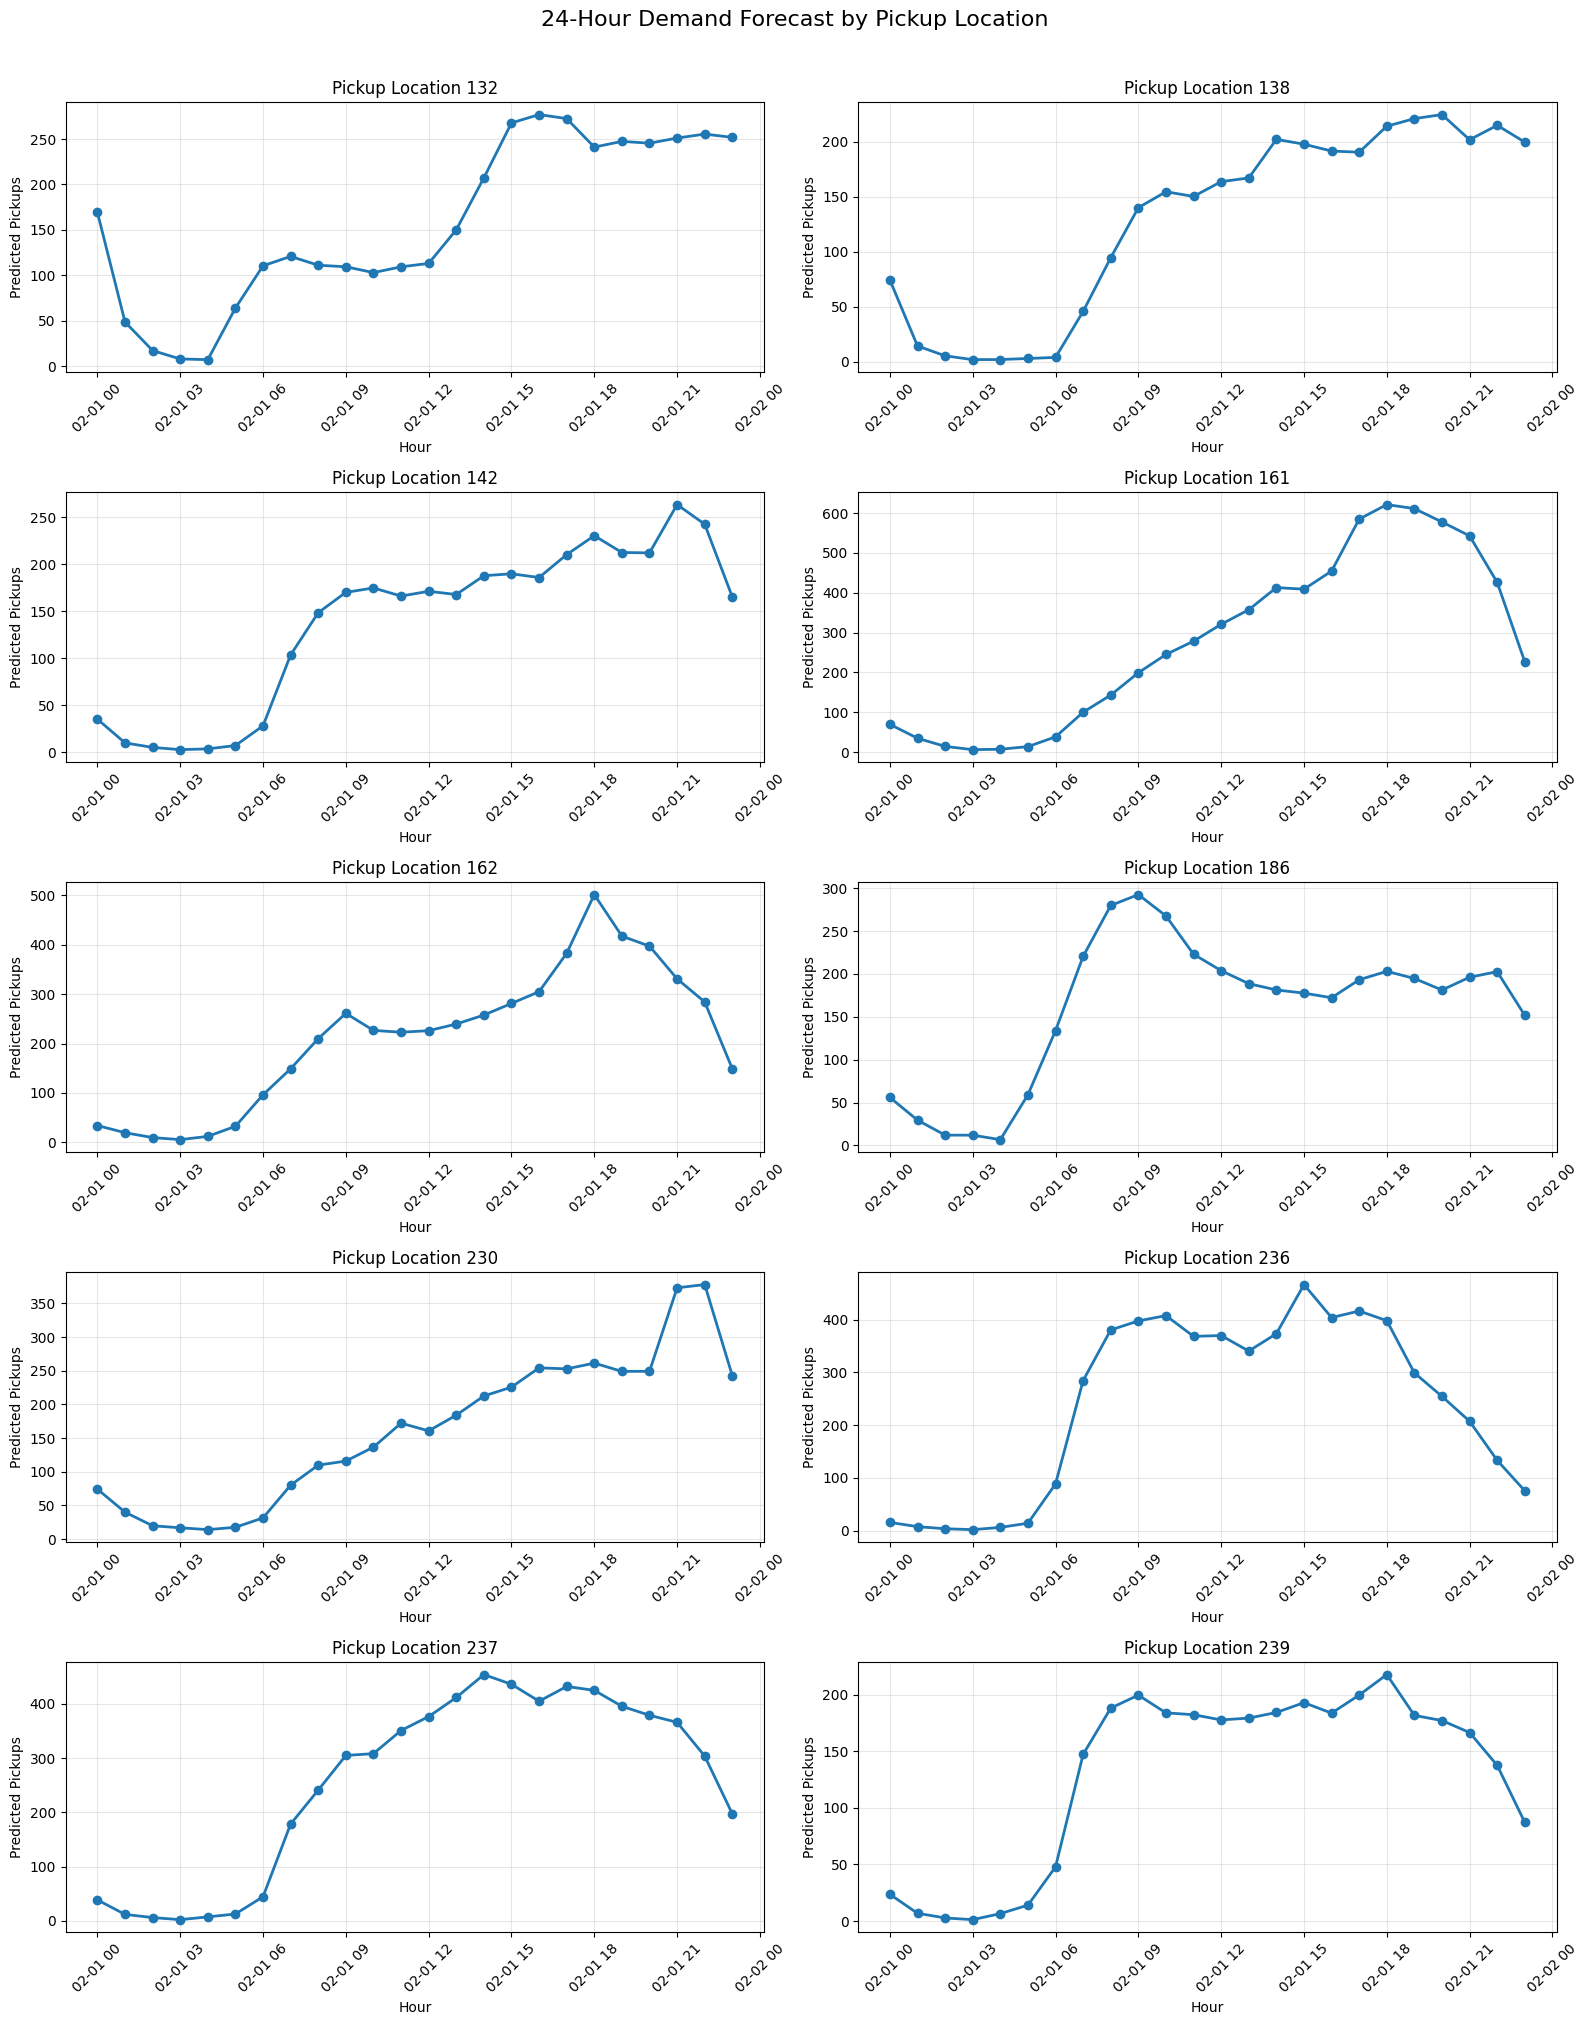

In [79]:
# Plot 24-hour demand forecast for each pickup location

locations = sorted(future_forecast_df["PULocationID"].unique())

fig, axes = plt.subplots(5, 2, figsize=(16, 20))
axes = axes.flatten()

for ax, location in zip(axes, locations):

    location_data = future_forecast_df[
        future_forecast_df["PULocationID"] == location
    ].sort_values("pickup_hour")

    ax.plot(
        location_data["pickup_hour"],
        location_data["predicted_demand"],
        marker="o",
        linewidth=2
    )

    ax.set_title(f"Pickup Location {location}")
    ax.set_xlabel("Hour")
    ax.set_ylabel("Predicted Pickups")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=45)

plt.suptitle(
    "24-Hour Demand Forecast by Pickup Location",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

### Location-wise 24-Hour Forecast - Observations
- Forecasted demand patterns vary significantly across pickup locations, indicating that taxi demand is geographically and temporally heterogeneous.
- Location 161 exhibits a strong increase in demand throughout the day, with high demand during evening hours.
- Location 162 shows a pronounced evening peak, followed by a decline in demand toward late night.
- Location 236 demonstrates strong morning demand and another notable peak during the afternoon.
- Location 237 experiences a sharp morning increase and maintains relatively high demand during most of the day.
- Location 132 shows an increase in demand around midday, followed by sustained demand during afternoon and evening hours.
- Locations 138 and 239 exhibit a sharp morning increase followed by relatively stable demand throughout the day.
- Location 142 shows low demand during early morning hours, followed by increasing demand and an evening peak.
- Location 186 experiences a sharp morning increase followed by relatively sustained demand.
- Location 230 shows increasing demand throughout the day, with notable peaks during late evening hours.

**Business Implication:** Fleet allocation should be location-specific and time-dependent rather than based on a single city-wide demand pattern. Forecasts can help reposition drivers toward locations expected to experience higher demand and reduce idle fleet capacity in low-demand areas.

In [82]:
# Summarize 24-hour forecast for each pickup location
display(future_forecast_df.head(5))
print('#'*50)
location_forecast_summary = (
    future_forecast_df
    .groupby("PULocationID")
    .agg(
        total_predicted_demand=("predicted_demand", "sum"),
        average_hourly_demand=("predicted_demand", "mean"),
        max_hourly_demand=("predicted_demand", "max"),
        min_hourly_demand=("predicted_demand", "min")
    )
    .reset_index()
)

# Identify peak hour for each location
peak_hours = (
    future_forecast_df.loc[
        future_forecast_df.groupby("PULocationID")["predicted_demand"].idxmax(),
        ["PULocationID", "pickup_hour", "predicted_demand"]
    ]
    .rename(columns={
        "pickup_hour": "peak_hour",
        "predicted_demand": "peak_demand"
    })
)

location_forecast_summary = location_forecast_summary.merge(
    peak_hours,
    on="PULocationID"
)

location_forecast_summary = location_forecast_summary.sort_values(
    "total_predicted_demand",
    ascending=False
)

display(location_forecast_summary)

,pickup_hour,PULocationID,predicted_demand
0,2024-02-01 00:00:00,132,169.376036
1,2024-02-01 01:00:00,132,48.840162
2,2024-02-01 02:00:00,132,17.406361
3,2024-02-01 03:00:00,132,8.154667
4,2024-02-01 04:00:00,132,7.409960


##################################################


,PULocationID,total_predicted_demand,average_hourly_demand,max_hourly_demand,min_hourly_demand,peak_hour,peak_demand
3,161,6697.925149,279.080215,621.332471,6.390484,2024-02-01 18:00:00,621.332471
8,237,6084.265960,253.511082,453.739414,2.118206,2024-02-01 14:00:00,453.739414
7,236,5709.341852,237.889244,466.168903,1.790913,2024-02-01 15:00:00,466.168903
4,162,5050.256530,210.427355,501.354565,5.518941,2024-02-01 18:00:00,501.354565
6,230,3872.051714,161.335488,378.015139,14.028317,2024-02-01 22:00:00,378.015139
5,186,3839.297063,159.970711,292.615668,6.684554,2024-02-01 09:00:00,292.615668
0,132,3760.256180,156.677341,276.874533,7.409960,2024-02-01 16:00:00,276.874533
2,142,3290.904622,137.121026,263.459128,2.512734,2024-02-01 21:00:00,263.459128
9,239,3087.676900,128.653204,217.646143,1.206425,2024-02-01 18:00:00,217.646143
1,138,3077.930032,128.247085,224.717726,1.769341,2024-02-01 20:00:00,224.717726


### Location-level Forecast Summary - Observations

- Location 161 has the highest forecasted total demand across the selected locations, with approximately 6,698 predicted pickups over the forecast horizon. Its peak demand is expected around 6 PM.
- Location 237 ranks second in total forecasted demand, with approximately 6,084 pickups, and reaches its peak around 2 PM.
- Location 236 is also a high-demand location, with approximately 5,709 predicted pickups and a peak around 3 PM.
- Location 162 is expected to experience its highest demand around 6 PM, with approximately 501 pickups per hour.
- Location 230 exhibits a distinct late-evening demand pattern, with its peak forecast around 10 PM.
- Locations 138 and 239 have relatively lower total forecasted demand compared to the other selected locations.
- Peak demand timings differ across locations, highlighting the importance of location-specific operational planning.

**Business Implication:** Locations 161, 237, 236, and 162 should receive priority for fleet availability during their forecasted peak periods. Location 230 may require additional fleet allocation during late evening hours. Demand forecasts can help optimize driver positioning, reduce idle time, and improve service availability.

## Dynamic Pricing Simulation

### Objective
- The objective of this simulation is to evaluate how different pricing strategies impact customer demand and total revenue.
- Since actual price elasticity is not directly available in the dataset, we use an assumed price elasticity value to simulate customer response to price changes.

### Price Elasticity of Demand
- Price elasticity measures how sensitive customer demand is to changes in price.

We use the constant elasticity demand model:

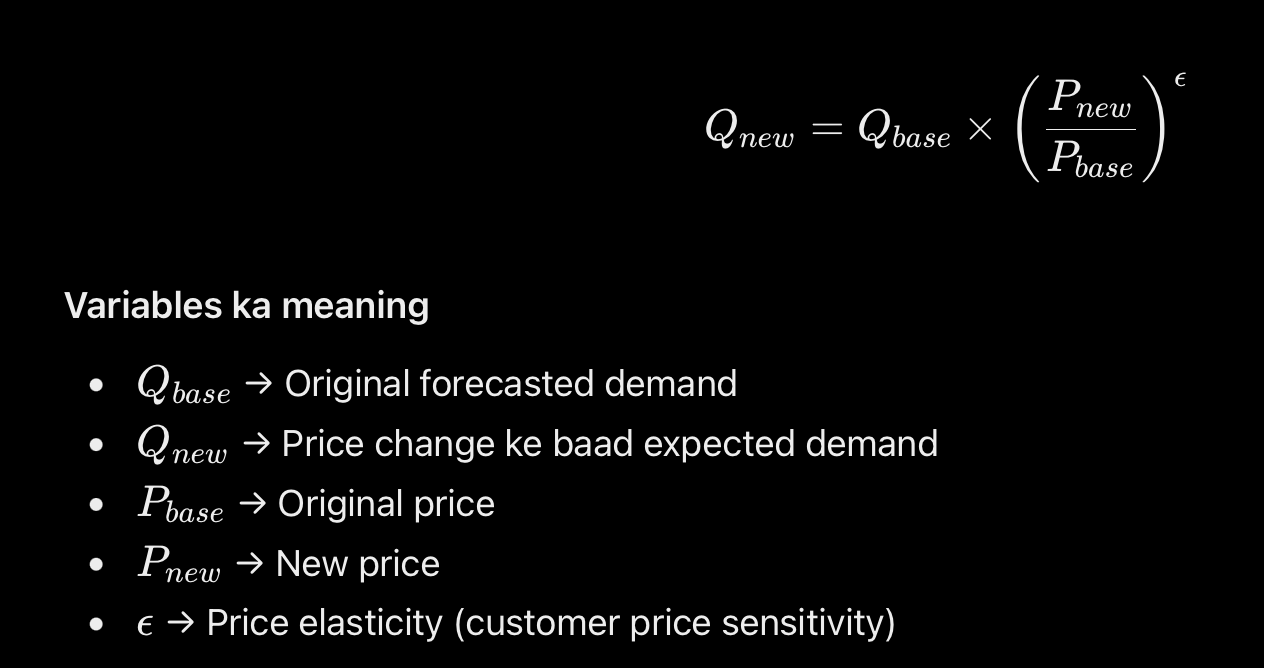

### Assumptions

- Base fare is assumed to be $15 per trip.
- Price elasticity is assumed to be -1.5.
- Price multipliers of 0.8, 0.9, 1.0, 1.1, and 1.2 are evaluated.
- A multiplier of 1.0 represents the baseline pricing strategy.
- Demand response is simulated using the constant elasticity formula.
- These elasticity assumptions are illustrative and are not estimated from the actual dataset.

### Pricing Scenarios

We evaluate the following pricing strategies:

| Price Multiplier | Pricing Strategy |
|---|---|
| 0.8 | 20% price decrease |
| 0.9 | 10% price decrease |
| 1.0 | No price change |
| 1.1 | 10% price increase |
| 1.2 | 20% price increase |

### Evaluation Metrics

For each pricing scenario, we calculate:

- Total simulated demand
- Simulated price per trip
- Total simulated revenue
- Revenue change compared with baseline

The goal is to identify the pricing strategy that generates the highest simulated revenue while understanding its impact on customer demand.

**Important:** This analysis is a scenario simulation based on assumed elasticity. The results should not be interpreted as actual causal impact. A real pricing strategy should be validated through controlled A/B testing.

In [84]:
# Dynamic Pricing Simulation - Baseline Scenario

# Assumed base fare for simulation
base_fare = 15  # USD per trip

# Baseline: No price change
baseline_multiplier = 1.0

baseline_data = future_forecast_df.copy()
print('Main Data')
display(baseline_data.head())
print('-'*50)
baseline_data["base_fare"] = base_fare
baseline_data["price_multiplier"] = baseline_multiplier
baseline_data["simulated_price"] = (
    baseline_data["base_fare"] * baseline_data["price_multiplier"]
)

# Under baseline pricing, demand remains unchanged
baseline_data["simulated_demand"] = baseline_data["predicted_demand"]

# Calculate revenue
baseline_data["revenue"] = (
    baseline_data["simulated_demand"] * baseline_data["simulated_price"]
)

display(baseline_data.head())

# Total baseline revenue
baseline_total_revenue = baseline_data["revenue"].sum()

print(f"Baseline Total Forecasted Demand: {baseline_data['simulated_demand'].sum():,.0f}")
print(f"Baseline Total Revenue: ${baseline_total_revenue:,.2f}")
print(f"Baseline Average Fare: ${base_fare:.2f}")

Main Data


,pickup_hour,PULocationID,predicted_demand
0,2024-02-01 00:00:00,132,169.376036
1,2024-02-01 01:00:00,132,48.840162
2,2024-02-01 02:00:00,132,17.406361
3,2024-02-01 03:00:00,132,8.154667
4,2024-02-01 04:00:00,132,7.409960


--------------------------------------------------


,pickup_hour,PULocationID,predicted_demand,base_fare,price_multiplier,simulated_price,simulated_demand,revenue
0,2024-02-01 00:00:00,132,169.376036,15,1.0,15.0,169.376036,2540.640536
1,2024-02-01 01:00:00,132,48.840162,15,1.0,15.0,48.840162,732.602435
2,2024-02-01 02:00:00,132,17.406361,15,1.0,15.0,17.406361,261.095417
3,2024-02-01 03:00:00,132,8.154667,15,1.0,15.0,8.154667,122.320000
4,2024-02-01 04:00:00,132,7.409960,15,1.0,15.0,7.409960,111.149405


Baseline Total Forecasted Demand: 44,470
Baseline Total Revenue: $667,048.59
Baseline Average Fare: $15.00


In [85]:
# Dynamic Pricing Simulation using assumed price elasticity
# Assumed price elasticity of demand
price_elasticity = -1.5

# Pricing scenarios
price_multipliers = [0.8, 0.9, 1.0, 1.1, 1.2]

pricing_scenarios = []

for multiplier in price_multipliers:

    # Calculate new price
    simulated_price = base_fare * multiplier

    # Demand response using constant elasticity formula
    simulated_demand = (
        baseline_data["predicted_demand"] *
        (multiplier ** price_elasticity)
    )

    # Calculate revenue
    simulated_revenue = simulated_demand * simulated_price

    pricing_scenarios.append({
        "Price_Multiplier": multiplier,
        "Price": simulated_price,
        "Total_Demand": simulated_demand.sum(),
        "Total_Revenue": simulated_revenue.sum()
    })

pricing_results = pd.DataFrame(pricing_scenarios)

# Compare revenue against baseline
pricing_results["Revenue_Change_vs_Baseline_%"] = (
    (pricing_results["Total_Revenue"] - baseline_total_revenue)
    / baseline_total_revenue
) * 100

display(pricing_results.round(2))

,Price_Multiplier,Price,Total_Demand,Total_Revenue,Revenue_Change_vs_Baseline_%
0,0.8,12.0,62148.58,745783.00,11.80
1,0.9,13.5,52083.77,703130.95,5.41
2,1.0,15.0,44469.91,667048.59,0.00
3,1.1,16.5,38545.81,636005.88,-4.65
4,1.2,18.0,33829.40,608929.27,-8.71


### Dynamic Pricing Simulation - Observations
- Under the assumed price elasticity of -1.5, reducing prices increases simulated demand and total revenue.
- A 20% price reduction ($12 fare) generates the highest simulated revenue of approximately $745,783.
- This represents an 11.80% increase in revenue compared with the baseline scenario.
- A 10% price reduction also improves revenue by approximately 5.41%.
- Increasing prices by 10% or 20% results in lower simulated revenue, with declines of approximately 4.65% and 8.71%, respectively.
- The results suggest that demand is relatively price-sensitive under the assumed elasticity.
- Lower prices increase demand sufficiently to offset the reduction in fare, resulting in higher simulated revenue.

**Conclusion:** Under the assumed elasticity of -1.5, the 20% price reduction scenario produces the highest revenue among the evaluated pricing strategies.

**Important Limitation:** These results are based on an assumed elasticity parameter and simplified demand-response model. They should not be interpreted as actual revenue gains. Real-world pricing decisions require validation through experimentation, such as an A/B test, and should consider driver availability, capacity constraints, operating costs, customer behavior, and regulatory restrictions.

### Revenue Comparison Across Pricing Scenarios

This visualization compares simulated revenue under different pricing multipliers.

The baseline scenario represents the current assumed fare of $15, while alternative scenarios evaluate the impact of increasing or decreasing fares.

The objective is to identify the pricing strategy that generates the highest simulated revenue under the assumed demand elasticity.

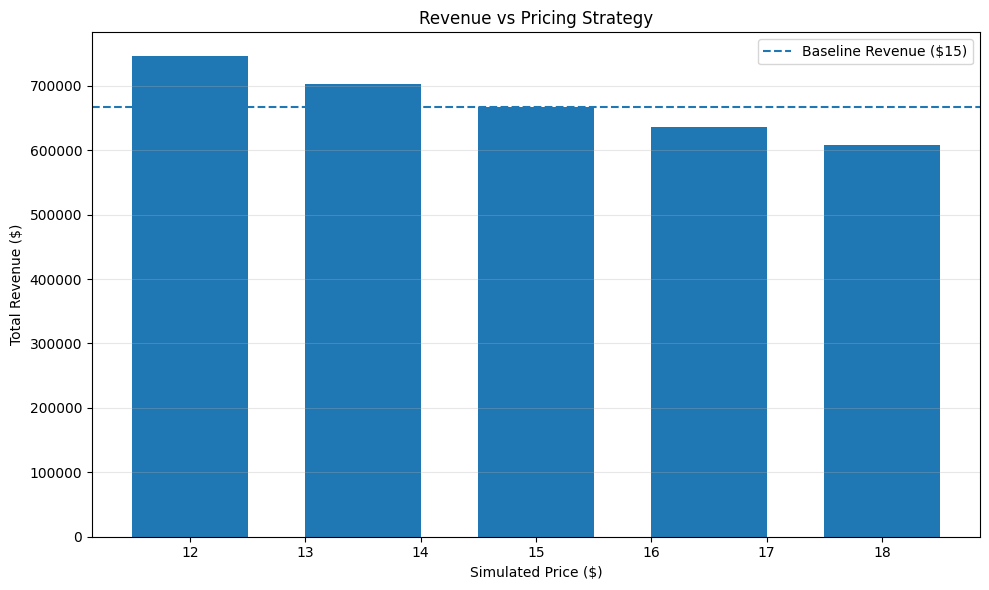

In [86]:
# Revenue comparison across pricing scenarios

plt.figure(figsize=(10, 6))

plt.bar(
    pricing_results["Price"],
    pricing_results["Total_Revenue"],
    width=1.0
)

# Highlight baseline revenue
plt.axhline(
    baseline_total_revenue,
    linestyle="--",
    label="Baseline Revenue ($15)"
)

plt.title("Revenue vs Pricing Strategy")
plt.xlabel("Simulated Price ($)")
plt.ylabel("Total Revenue ($)")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Elasticity Sensitivity Analysis

### Objective

The pricing simulation currently uses an assumed price elasticity of -1.5.

Since the actual price elasticity of taxi customers is unknown, we perform sensitivity analysis to evaluate how pricing recommendations change under different elasticity assumptions.

### Elasticity Scenarios

| Elasticity | Interpretation |
|---|---|
| -0.5 | Relatively price-insensitive demand |
| -1.0 | Unit elasticity |
| -1.5 | More price-sensitive demand |
| -2.0 | Highly price-sensitive demand |

For each elasticity scenario, we evaluate multiple price multipliers and calculate simulated demand and revenue.

This helps determine whether the recommended pricing strategy remains consistent across different assumptions.

In [88]:
# Elasticity sensitivity analysis

elasticity_values = [-0.5, -1.0, -1.5, -2.0]
price_multipliers = [0.8, 0.9, 1.0, 1.1, 1.2]

sensitivity_results = []

for elasticity in elasticity_values:

    for multiplier in price_multipliers:

        simulated_price = base_fare * multiplier

        simulated_demand = (
            baseline_data["predicted_demand"] *
            (multiplier ** elasticity)
        )

        simulated_revenue = (
            simulated_demand * simulated_price
        )

        sensitivity_results.append({
            "Elasticity": elasticity,
            "Price_Multiplier": multiplier,
            "Price": simulated_price,
            "Total_Demand": simulated_demand.sum(),
            "Total_Revenue": simulated_revenue.sum()
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(2))

,Elasticity,Price_Multiplier,Price,Total_Demand,Total_Revenue
0,-0.5,0.8,12.0,49718.87,596626.40
1,-0.5,0.9,13.5,46875.40,632817.86
2,-0.5,1.0,15.0,44469.91,667048.59
3,-0.5,1.1,16.5,42400.39,699606.46
4,-0.5,1.2,18.0,40595.28,730715.12
5,-1.0,0.8,12.0,55587.38,667048.59
6,-1.0,0.9,13.5,49411.01,667048.59
7,-1.0,1.0,15.0,44469.91,667048.59
8,-1.0,1.1,16.5,40427.19,667048.59
9,-1.0,1.2,18.0,37058.26,667048.59


### Price Elasticity Sensitivity Analysis - Observations

- The optimal pricing strategy varies depending on the assumed price elasticity of demand.
- Under an elasticity of -0.5, customers are relatively less sensitive to price changes, and the $18 fare generates the highest simulated revenue among the evaluated scenarios.
- Under an elasticity of -1.0, simulated revenue remains constant across all pricing scenarios, consistent with unit elasticity under the constant elasticity model.
- Under elasticity values of -1.5 and -2.0, lower prices generate higher simulated revenue because the increase in demand offsets the reduction in price.
- The $12 pricing scenario generates the highest revenue under elasticity assumptions of -1.5 and -2.0.
- The highest simulated revenue across all tested scenarios is approximately $833,811, achieved at a $12 fare under an elasticity assumption of -2.0.

**Key Insight:** There is no universally optimal price under this simulation. The optimal pricing strategy depends heavily on customer price sensitivity.

**Business Implication:** Before implementing dynamic pricing, the business should estimate actual price elasticity through historical pricing experiments or controlled A/B testing. Sensitivity analysis helps quantify the risk of making pricing decisions using uncertain elasticity assumptions.

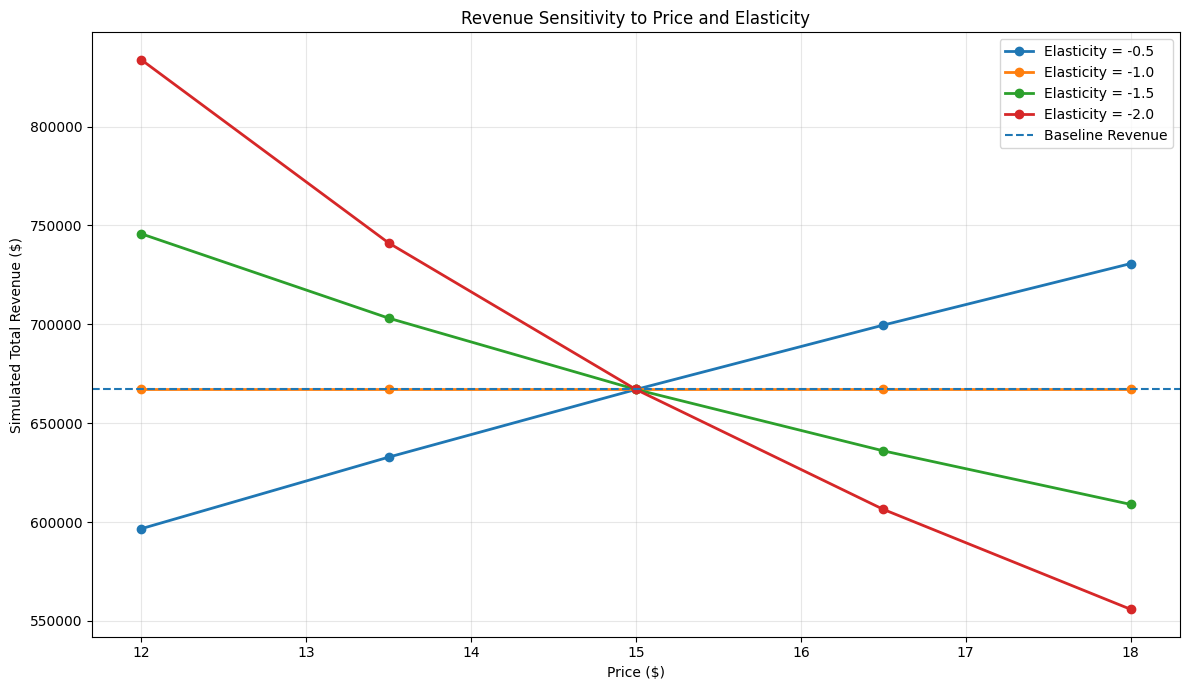

In [89]:
# Revenue sensitivity across different elasticity assumptions

plt.figure(figsize=(12, 7))

for elasticity in elasticity_values:

    subset = sensitivity_df[
        sensitivity_df["Elasticity"] == elasticity
    ].sort_values("Price")

    plt.plot(
        subset["Price"],
        subset["Total_Revenue"],
        marker="o",
        linewidth=2,
        label=f"Elasticity = {elasticity}"
    )

plt.axhline(
    baseline_total_revenue,
    linestyle="--",
    label="Baseline Revenue"
)

plt.title("Revenue Sensitivity to Price and Elasticity")
plt.xlabel("Price ($)")
plt.ylabel("Simulated Total Revenue ($)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [90]:
# Identify the best pricing scenario under each elasticity assumption

optimal_pricing = (
    sensitivity_df
    .sort_values("Total_Revenue", ascending=False)
    .groupby("Elasticity")
    .head(1)
    .sort_values("Elasticity")
    .reset_index(drop=True)
)

optimal_pricing["Revenue_Improvement_%"] = (
    (optimal_pricing["Total_Revenue"] - baseline_total_revenue)
    / baseline_total_revenue
) * 100

display(optimal_pricing.round(2))

,Elasticity,Price_Multiplier,Price,Total_Demand,Total_Revenue,Revenue_Improvement_%
0,-2.0,0.8,12.0,69484.23,833810.74,25.00
1,-1.5,0.8,12.0,62148.58,745783.00,11.80
2,-1.0,1.1,16.5,40427.19,667048.59,0.00
3,-0.5,1.2,18.0,40595.28,730715.12,9.54


### Elasticity Sensitivity Analysis - Key Findings

- The optimal pricing strategy changes depending on the assumed price elasticity of demand.
- When elasticity is -0.5, customers are relatively less price-sensitive. Increasing the fare to $18 produces the highest simulated revenue of approximately $730,715, representing a 9.54% increase over baseline.
- When elasticity is -1.0, revenue remains constant across all tested pricing scenarios under the constant elasticity model.
- When elasticity is -1.5, reducing the fare to $12 produces the highest simulated revenue of approximately $745,783, representing an 11.80% improvement over baseline.
- When elasticity is -2.0, the $12 fare generates the highest simulated revenue of approximately $833,811, representing a 25.00% improvement over baseline.
- The sensitivity analysis demonstrates that pricing decisions are highly dependent on customer price sensitivity.

**Key Business Insight:** A single pricing strategy may not be optimal across all customer segments or locations. Pricing decisions should ideally be based on estimated elasticity and validated through controlled experiments.

**Recommendation:** Estimate actual price elasticity using historical pricing variation or A/B testing before implementing a production dynamic pricing strategy.

## A/B Testing Strategy for Dynamic Pricing

### Objective

Validate whether dynamic pricing improves revenue without negatively impacting customer experience, ride completion rates, or driver availability.

### Experiment Design

- **Control Group (A):** Customers receive the baseline pricing strategy.
- **Treatment Group (B):** Customers receive pricing adjustments based on forecasted demand.
- Customers or eligible trips should be randomly assigned to the groups.
- The experiment should run across comparable locations and time periods to minimize bias.

### Primary Metric

- Revenue per eligible ride request

### Secondary Metrics

- Ride conversion rate
- Number of completed trips
- Average fare
- Customer cancellation rate
- Driver utilization
- Customer complaints

### Hypothesis

**Null Hypothesis (H₀):** Dynamic pricing does not significantly improve revenue per eligible ride request compared with baseline pricing.

**Alternative Hypothesis (H₁):** Dynamic pricing significantly improves revenue per eligible ride request compared with baseline pricing.

### Decision Criteria

Dynamic pricing should be rolled out only if:

1. Revenue improvement is statistically significant.
2. Ride conversion and completion rates do not deteriorate beyond acceptable thresholds.
3. Customer cancellation and complaint rates remain within acceptable limits.
4. Driver supply is sufficient to serve the increased demand.

### Conclusion

The forecasting model and pricing simulation provide a framework for identifying demand patterns and evaluating potential pricing strategies. However, simulated revenue improvements are based on assumed elasticity and must be validated using real-world experimentation before implementation.

# Final Business Recommendations

## 1. Demand Forecasting

- Random Forest performed better than the Weekly Seasonal Naive baseline and Day-Hour Pattern model on the test dataset.
- Random Forest achieved a WAPE of approximately 13.96%, compared with 14.62% for the Weekly Seasonal Naive baseline.
- Demand patterns differ across pickup locations and time periods.
- Forecasts should be used to support location-specific fleet positioning and operational planning.

## 2. Fleet Optimization

- Prioritize high-demand pickup locations such as Location 161, 237, 236, and 162.
- Allocate additional drivers during forecasted peak demand periods.
- Identify low-demand periods to reduce idle fleet capacity and optimize driver scheduling.
- Use location-level forecasts rather than relying only on city-wide demand estimates.

## 3. Dynamic Pricing

- The pricing simulation indicates that revenue outcomes depend heavily on assumed price elasticity.
- Under elasticity of -1.5, a 20% price reduction generates the highest simulated revenue among the evaluated scenarios.
- Under elasticity of -0.5, increasing prices generates higher simulated revenue.
- Therefore, a single pricing strategy may not be optimal across all customer segments, locations, and time periods.

## 4. Data-Driven Pricing Strategy

- Forecast demand at location and hourly level.
- Identify demand peaks and low-demand periods.
- Evaluate pricing scenarios using estimated customer price sensitivity.
- Consider driver availability and operational capacity before applying price adjustments.
- Validate pricing strategies through controlled experiments before large-scale deployment.

## 5. Experimentation

- Conduct an A/B test comparing baseline pricing with a demand-based pricing strategy.
- Monitor revenue per eligible ride request as the primary metric.
- Track conversion rate, completed rides, cancellations, customer complaints, and driver utilization.
- Roll out pricing changes only when measurable business benefits are observed without unacceptable customer impact.

# Limitations

## 1. Limited Historical Data

The analysis uses January 2024 data only. Seasonal patterns, holidays, weather effects, special events, and longer-term trends may not be captured.

## 2. Forecasting Model Limitations

- The Random Forest model is evaluated using a limited test period.
- Forecast accuracy may vary across locations.
- The current recursive 24-hour forecasting approach can accumulate prediction errors as forecasts progress.
- The model primarily relies on historical demand patterns and lag features.

## 3. Missing External Variables

The model does not incorporate external factors such as:

- Weather conditions
- Public holidays
- Events and concerts
- Traffic conditions
- Flight arrivals and departures
- Road closures
- Taxi availability and driver supply

These factors may significantly influence demand.

## 4. Pricing Simulation Assumptions

- Base fare is assumed to be $15.
- Price elasticity is assumed rather than estimated from actual customer behavior.
- The demand response follows a constant elasticity model.
- The simulation does not account for price competition, customer fairness perception, regulatory constraints, or changes in driver supply.

Therefore, simulated revenue improvements should not be interpreted as guaranteed real-world outcomes.

## 5. Operational Constraints

The simulation assumes predicted demand can be served. In practice, driver availability, vehicle capacity, waiting times, service coverage, and operational constraints may limit the number of completed trips.

## 6. Need for Experimentation

The proposed pricing strategy should be validated using an A/B test or another controlled experiment before implementation.

# Executive Conclusion

This case study demonstrates how historical taxi trip data can be used to build a demand forecasting framework and evaluate potential dynamic pricing strategies.

The analysis identified temporal and geographical variations in taxi demand across pickup locations. Multiple forecasting approaches were evaluated, with the Random Forest model achieving the best overall performance among the tested models, with a WAPE of approximately 13.96%.

The forecasts were further used to simulate different pricing strategies under varying price elasticity assumptions. The sensitivity analysis demonstrated that the optimal pricing strategy depends significantly on customer price sensitivity.

The analysis suggests opportunities to improve fleet allocation, reduce idle capacity, increase service availability during peak demand periods, and potentially optimize revenue through demand-based pricing.

However, pricing recommendations are based on simulated assumptions rather than observed causal effects. Before implementation, price elasticity should be estimated using real-world data and pricing strategies should be validated through controlled experimentation.

### Key Takeaways

- Historical data can support demand forecasting at hourly and pickup-location levels.
- Random Forest outperformed the tested baseline forecasting approaches.
- Taxi demand patterns vary significantly by location and time.
- Demand forecasts can support driver positioning and fleet optimization.
- Dynamic pricing outcomes are highly sensitive to customer price elasticity.
- A/B testing is essential before implementing pricing changes.

**Overall, the proposed framework combines demand forecasting, operational optimization, and pricing experimentation to support data-driven decision-making in taxi operations.**